# ♟️ Chess Numba — Classical HCE Texel / SPSA 分區調參工作台

在完成 `evaluation.py` 的 **8 項錯誤修復與順序修正**（`BUG-1..8`、`ORD-1..3`、`KP-DISCONT`）後，本 Notebook 提供**單一 Kernel、免重載資料、免重編譯 Numba** 的互動式區塊調參流程。

### 🛡️ 核心設計：自動尺度對齊 ($K^*$)、模式切換、SF19 混合標籤與記憶體安全
1. **`dataset_epd_wdl_20m.npz`（~19,630,000 局面）無洩漏三切分**：
   - **`~16.6M` Train Pool**（16 GB RAM 自動抽樣 `10M` 防 Swap）：僅供 SPSA mini-batch 梯度估計。
   - **`1,000,000` Dev Split (`rng=0`)**：供 SPSA 過程報告、early stopping 與**自動校準 $K^*$ (`k_factor="auto"`)**，徹底消除固定 `K=1.0` 造成的假性尺度膨脹。
   - **`2,000,000` Unseen Holdout (`rng=42`)**：**完全不進訓練、也不進 early stop，且永遠維持純 WDL 評估**，作為第一道靜態驗收閘門。
2. **可切換獨立驗證集（`USE_PGN_VAL` / `USE_ZURICHESS_VAL`）**：
   - **`USE_PGN_VAL = True`（預設雙重驗證）**：同時以 `2M unseen holdout` + `val_pgn.npz`（1.59M 實戰局面，含 `castling!=0` 易位權桶與校準 $K^*$）把關。
   - **`USE_PGN_VAL = False`（純 Holdout 對照模式）**：略過 `val_pgn.npz` 載入與評估，僅依 `2M unseen holdout (@ K*)` 判定。
   - **`USE_ZURICHESS_VAL`（選用第三平靜仲裁集）**：需要時可設 `True` 載入 `val_zurichess.npz`（1.08M 平靜局面，含 13.53% 易位權）。
3. **可切換 SF19 搜尋評估＋WDL 線性混合標籤（`USE_SF_LABELS` & `SF_LAMBDA`）**：
   - 先在終端機執行 `python -m tuner.data_pipeline.annotate_sf_labels` 產生輕量側車檔 `dataset_epd_wdl_20m.sf19.npz`（~35 MB，支援 `Ctrl+C` 中斷續傳與 `--limit` 子集先行測試）。
   - 開啟 `USE_SF_LABELS = True` 後，Session 會在 `train_idx` 上自動擬合無偏 $K_{	ext{sf}}$，於記憶體動態合成 $y_{	ext{mix}} = (1 - \lambda)\, y_{	ext{wdl}} + \lambda\, \sigma(K_{	ext{sf}} \cdot 	ext{sf\_cp})$（並自動剔除 $|	ext{sf\_cp} - 	ext{sf\_d1\_cp}| > 180$ 的戰術跳分局面），同時保持 `2M unseen holdout` 與 `val_pgn` 為**純 WDL** 不變尺規。
4. **目標引擎選擇 (`TARGET_ENGINE`) 與零重載切換 (`session.reconfigure`)**：
   - `"classical"` 寫入 `chess_engine/classical/constants.py`；`"classical_old"` 寫入 `chess_engine/classical_old/constants.py`，輸出與備份自動隔離至 `tuner/runs/<engine>_<mode>[_sfXX]/`。
   - 修改 `# 0` 開關後重跑 `# 0`，自動複用記憶體中的 20M 資料集（~3 秒切換，防 16 GB 機器 OOM）。
5. **Google Colab + Google Drive 雲端執行與斷線防護（`# 00` & `# 9d`）**：
   - 本機執行自動略過 `# 00`；在 Colab 會自動掛載 Google Drive，將 `MyDrive/chess_numba_data/hce/` 資料集複製到本機 SSD，並把每次 `accept()` / `rollback()` / 候選檔即時備份至 `MyDrive/chess_numba_data/texel_runs/`（支援 `RESUME_FROM_DRIVE = True` 斷線續跑）。

### 🚦 Gate Verdict 驗收標準（已升級 $K^*$ 防膨脹守衛）
- `PASS`：`2M unseen holdout` 在校準尺度 $K^*$ 顯著下降（`delta < 0` 且無尺度扭曲）、`broad-EG (phase<=64)` 未惡化（$z \le 1.0$）；若啟用 `val_pgn`，其 $K^*$ 無退步（$z \le 1.2$，排除 $< 1.2\,	ext{SE}$ 微小統計雜訊）且 `castling!=0` 穩定。
- `CAUTION`：主驗證集改善，但子桶或獨立驗證集微幅偏正（$1.0 < z \le 2.0$）。
- `REJECT`：Holdout 在 $K^*$ 退步、`broad-EG` 顯著惡化（$z > 1.8$），或 `val_pgn @ K*` 顯著惡化（$z > 2.0\sim2.5$）→ **自動跳過不套用**。

In [1]:
# =====================================================================
# 檢視 Colab 雲端硬體規格與 CPU 核心數
# =====================================================================
!lscpu | grep "Model name\|Socket\|Thread\|NUMA\|CPU(s)"
!free -h
!python3 --version


CPU(s):                                  8
On-line CPU(s) list:                     0-7
Model name:                              AMD EPYC 7B12
Thread(s) per core:                      2
Socket(s):                               1
NUMA node(s):                            1
NUMA node0 CPU(s):                       0-7
               total        used        free      shared  buff/cache   available
Mem:            50Gi       1.4Gi        47Gi       2.2Mi       2.7Gi        49Gi
Swap:             0B          0B          0B
Python 3.13.18


In [2]:
# 00. 【Colab / Google Drive 環境初始化】（本機執行會自動略過，直接保留本機路徑與資料）
import importlib.util
import os
import shutil
import subprocess
import sys
from pathlib import Path

IN_COLAB = ("google.colab" in sys.modules) or (os.name != "nt" and Path("/content").is_dir())

# ==============================================================================
# Colab / Google Drive 設定（僅在 Google Colab 環境生效）
# ==============================================================================
REPO_URL = "https://github.com/b08203031/chess_numba.git"
BRANCH = "feat-initial-bitboard-setup"
WORKDIR = Path("/content/chess_numba")

# Google Drive 資料目錄：請先手動將 dataset_epd_wdl_20m.npz 與 val_pgn.npz 上傳到此資料夾
DRIVE_DATA_DIR = Path("/content/drive/MyDrive/chess_numba_data/hce")
# 調參產物 (runs / backups / 最新 constants.py) 會即時備份至此 Drive 目錄，防斷線遺失
DRIVE_BACKUP_DIR = Path("/content/drive/MyDrive/chess_numba_data/texel_runs")
# 若 Colab 中途斷線，重跑想接續 Drive 上最後一次 Accept 的 constants.py，請改為 True
RESUME_FROM_DRIVE = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    print("=== Colab 硬體與記憶體規格 ===")
    subprocess.run(["bash", "-lc", "lscpu | grep -E 'Model name|CPU\\(s\\)' || nproc"], check=False)
    subprocess.run(["free", "-h"], check=False)

    # 1) Clone 或更新 GitHub 程式碼（不用 git clean -fd，避免誤刪已複製的資料與快取）
    if not (WORKDIR / ".git").is_dir():
        print(f"\n[Git] Cloning {REPO_URL} (branch={BRANCH}) -> {WORKDIR} ...")
        subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, str(WORKDIR)], check=True)
    else:
        print(f"\n[Git] Syncing {WORKDIR} -> origin/{BRANCH} ...")
        subprocess.run(["git", "-C", str(WORKDIR), "fetch", "origin", BRANCH], check=True)
        subprocess.run(["git", "-C", str(WORKDIR), "checkout", "-f", BRANCH], check=True)
        subprocess.run(["git", "-C", str(WORKDIR), "reset", "--hard", f"origin/{BRANCH}"], check=True)

    os.chdir(WORKDIR)

    # 2) 僅安裝 Colab 缺少的必要相依套件（保留預裝相容之 NumPy / Numba / SciPy 組合）
    missing_pkgs = [
        pkg
        for mod, pkg in (
            ("numba", "numba"),
            ("numpy", "numpy"),
            ("scipy", "scipy"),
            ("chess", "chess"),
        )
        if importlib.util.find_spec(mod) is None
    ]
    if missing_pkgs:
        print(f"[Pip] Installing missing packages: {missing_pkgs}")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing_pkgs], check=True)

    # 3) 檢查 / 還原斷線續跑備份
    DRIVE_BACKUP_DIR.mkdir(parents=True, exist_ok=True)
    if RESUME_FROM_DRIVE:
        restored = []
        for eng in ("classical", "classical_old"):
            saved = DRIVE_BACKUP_DIR / f"{eng}_constants.py"
            dst_c = WORKDIR / "chess_engine" / eng / "constants.py"
            if saved.is_file():
                shutil.copy2(saved, dst_c)
                restored.append(eng)
                print(f"[Resume] 已從 Drive 還原 {eng}/constants.py <- {saved}")
        # 同步先前的 runs 子目錄（含 backups/ 與已產生的 block_*.py）
        for sub in DRIVE_BACKUP_DIR.iterdir():
            if sub.is_dir():
                dst_run = WORKDIR / "tuner" / "runs" / sub.name
                shutil.copytree(sub, dst_run, dirs_exist_ok=True)
                print(f"[Resume] 已還原歷史調參紀錄 -> {dst_run}")
        if restored:
            subprocess.run([sys.executable, "-m", "tuner.sync_constants_snapshot"], check=True)
        if "classical_old" in restored:
            subprocess.run(
                [
                    sys.executable,
                    "-c",
                    "from pathlib import Path; "
                    "from tuner.sync_constants_snapshot import clear_classical_numba_cache; "
                    "clear_classical_numba_cache(Path('chess_engine/classical_old/__pycache__'))",
                ],
                check=True,
            )
    else:
        for eng in ("classical", "classical_old"):
            saved = DRIVE_BACKUP_DIR / f"{eng}_constants.py"
            if saved.is_file():
                print(
                    f"[Info] 偵測到 Drive 上已有備份：{saved}\n"
                    "       目前 RESUME_FROM_DRIVE=False（將從 GitHub 最新基準重新起跑）；"
                    "若要從上次斷線處續跑，請改設 RESUME_FROM_DRIVE=True 後重跑本 Cell。"
                )

    # 4) 從 Google Drive 複製資料集到 Colab 本機 SSD（比直接從 Drive FUSE 讀取快 ~10x）
    local_data_dir = WORKDIR / "tuner" / "data" / "hce"
    local_data_dir.mkdir(parents=True, exist_ok=True)
    if not DRIVE_DATA_DIR.is_dir():
        DRIVE_DATA_DIR.mkdir(parents=True, exist_ok=True)
        raise FileNotFoundError(
            f"找不到 Drive 資料夾或尚未上傳檔案：{DRIVE_DATA_DIR}\n"
            "請先手動將本機 tuner/data/hce/ 中的檔案上傳至 Google Drive 'MyDrive/chess_numba_data/hce/'：\n"
            "  1) dataset_epd_wdl_20m.npz（必備，~674 MB）\n"
            "  2) val_pgn.npz（開 USE_PGN_VAL=True 時必備，~22.7 MB）\n"
            "  3) val_zurichess.npz / dataset_epd_wdl_20m.sf19.npz（選用）"
        )

    data_files = [
        ("dataset_epd_wdl_20m.npz", True),
        ("val_pgn.npz", False),
        ("val_zurichess.npz", False),
        ("dataset_epd_wdl_20m.sf19.npz", False),
    ]
    for fname, required in data_files:
        src = DRIVE_DATA_DIR / fname
        dst = local_data_dir / fname
        if src.is_file():
            if dst.is_file() and dst.stat().st_size == src.stat().st_size:
                print(f"[Data] 本機 SSD 已存在最新 {fname} ({dst.stat().st_size / (1024**2):.1f} MB)，略過複製。")
            else:
                print(f"[Data] 正在從 Drive 複製 {fname} ({src.stat().st_size / (1024**2):.1f} MB) -> 本機 SSD ...")
                shutil.copy2(src, dst)
        elif required:
            raise FileNotFoundError(
                f"Google Drive 缺少必備訓練檔：{src}\n"
                "請先手動將本機 tuner/data/hce/dataset_epd_wdl_20m.npz 上傳至 Drive 'MyDrive/chess_numba_data/hce/'。"
            )
        elif fname == "val_pgn.npz":
            print("[WARN] Drive 中未找到 val_pgn.npz；若下方要設 USE_PGN_VAL=True 請先手動上傳。")
        else:
            print(f"[Data] 選用檔 {fname} 未提供（未啟用該功能時可略過）。")

    print(f"\n✅ Colab + Google Drive 環境與資料就緒！即時備份目錄：{DRIVE_BACKUP_DIR}")
else:
    DRIVE_BACKUP_DIR = None
    print("✅ 偵測為本機環境，略過 Colab/Drive 掛載（直接使用本機 tuner/data/hce/）。")

Mounted at /content/drive
=== Colab 硬體與記憶體規格 ===

[Git] Cloning https://github.com/b08203031/chess_numba.git (branch=feat-initial-bitboard-setup) -> /content/chess_numba ...
[Pip] Installing missing packages: ['chess']
[Data] 正在從 Drive 複製 dataset_epd_wdl_20m.npz (674.2 MB) -> 本機 SSD ...
[Data] 正在從 Drive 複製 val_pgn.npz (22.7 MB) -> 本機 SSD ...
[Data] 選用檔 val_zurichess.npz 未提供（未啟用該功能時可略過）。
[Data] 選用檔 dataset_epd_wdl_20m.sf19.npz 未提供（未啟用該功能時可略過）。

✅ Colab + Google Drive 環境與資料就緒！即時備份目錄：/content/drive/MyDrive/chess_numba_data/texel_runs


In [4]:
# 0. 環境檢查與載入 TexelTuningSession（首次載入約 25~45 秒；切換模式重跑本 Cell 僅需 ~3 秒）
import os
import sys
from pathlib import Path

# 自動定位專案根目錄（相容本機與 Colab）
if Path("chess_engine").is_dir() and Path("tuner").is_dir():
    REPO_ROOT = Path.cwd()
elif (Path.cwd().parent / "chess_engine").is_dir() and Path.cwd().name == "tuner":
    REPO_ROOT = Path.cwd().parent
    os.chdir(REPO_ROOT)
elif Path("/content/chess_numba").is_dir():
    REPO_ROOT = Path("/content/chess_numba")
    os.chdir(REPO_ROOT)
else:
    raise RuntimeError(f"請在專案根目錄啟動 Notebook，目前目錄：{Path.cwd()}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from tuner.notebook_session import TexelTuningSession

TRAIN_NPZ = REPO_ROOT / "tuner" / "data" / "hce" / "dataset_epd_wdl_20m.npz"
PGN_VAL_NPZ = REPO_ROOT / "tuner" / "data" / "hce" / "val_pgn.npz"
ZURICHESS_VAL_NPZ = REPO_ROOT / "tuner" / "data" / "hce" / "val_zurichess.npz"

# ==============================================================================
# 實驗模式參數（切換任一參數後直接重跑本 Cell，自動複用已載入的 20M 資料集，約 3 秒完成）
# ==============================================================================
# 1) 獨立驗證集選擇
USE_PGN_VAL = True            # True = 啟用 2M holdout + val_pgn.npz 雙重閘門；False = 僅用 2M unseen holdout
USE_ZURICHESS_VAL = False     # True = 額外啟用 val_zurichess.npz 第三平靜仲裁集（含 13.53% 易位權）

# 2) 訓練寫入目標引擎："classical"     -> chess_engine/classical/constants.py
#                    "classical_old" -> chess_engine/classical_old/constants.py
TARGET_ENGINE = "classical"

# 3) SF19 搜尋評估 + WDL 線性混合標籤：y_mix = (1 - SF_LAMBDA)*WDL + SF_LAMBDA*sigmoid(K_sf * sf_cp)
#    啟用前請先於終端機產生側車標籤檔（支援 Ctrl+C 續傳；可加 --limit 3000000 先跑快速前導實驗）：
#      python -m tuner.data_pipeline.annotate_sf_labels --nodes 4000 --skip-holdout
USE_SF_LABELS = False
SF_LAMBDA = 0.25              # 推薦 0.20 ~ 0.25（上限建議 <= 0.35；Unseen Holdout 與 val_pgn 永遠維持純 WDL）
SF_MAX_TACTICAL_GAP = 180     # |sf_cp - sf_d1_cp| > 180cp 的非平靜戰術局面自動排除出訓練梯度

# "auto": 若本機可用實體 RAM < 4.8 GB 自動取 10M train + 完整 1M dev + 2M holdout 防 Swap；設 None 強制載滿 17M train
MAX_TRAIN_ROWS = "auto"

if (
    "session" in globals()
    and getattr(session, "train_path", None) == TRAIN_NPZ
    and hasattr(session, "train_data")
):
    session.__class__ = TexelTuningSession
    session.reconfigure(
        use_pgn_val=USE_PGN_VAL,
        use_zurichess_val=USE_ZURICHESS_VAL,
        zurichess_val_npz=ZURICHESS_VAL_NPZ,
        target_engine=TARGET_ENGINE,
        pgn_val_npz=PGN_VAL_NPZ,
        use_sf_labels=USE_SF_LABELS,
        sf_lambda=SF_LAMBDA,
        sf_max_tactical_gap=SF_MAX_TACTICAL_GAP,
        drive_backup_dir=globals().get("DRIVE_BACKUP_DIR", None),
    )
else:
    session = TexelTuningSession(
        train_npz=TRAIN_NPZ,
        pgn_val_npz=PGN_VAL_NPZ,
        eval_sample=1_000_000,     # SPSA in-run dev / early-stop / K* 校準
        holdout_sample=2_000_000,  # 完全未見的訓練來源 holdout (永遠純 WDL)
        max_train_rows=MAX_TRAIN_ROWS,
        chunk_size=500_000,
        use_pgn_val=USE_PGN_VAL,
        use_zurichess_val=USE_ZURICHESS_VAL,
        zurichess_val_npz=ZURICHESS_VAL_NPZ,
        target_engine=TARGET_ENGINE,
        use_sf_labels=USE_SF_LABELS,
        sf_lambda=SF_LAMBDA,
        sf_max_tactical_gap=SF_MAX_TACTICAL_GAP,
        drive_backup_dir=globals().get("DRIVE_BACKUP_DIR", None),
    )
# 開啟「全自動無腦運行模式」：連續執行全部 Cell 時，僅當 Gate 判定為 PASS 才套用變更至目標 constants.py
session.require_pass_to_accept = True
print(
    f"[GUARD] 自動守衛已啟用：require_pass=True | target={session.target_engine!r} | "
    f"use_pgn_val={session.use_pgn_val} | use_sf_labels={session.use_sf_labels} "
    f"(lambda={session.sf_lambda:.2f}) | auto_K*={session._step_dev_k_star:.3f}"
)

[1/4] Loading primary dataset: dataset_epd_wdl_20m.npz (RAM before: 48.14 GB free / 50.99 GB total)
      Loaded 19,627,749 positions -> active_train=16,627,749 | active_dev=1,000,000 | unseen_holdout(WDL)=2,000,000 (RAM now: 44.54 GB free / 50.99 GB total)
[2/4] Loading independent PGN validation set: val_pgn.npz
      Loaded 1,593,187 unique PGN positions (castling!=0: 104,249 [6.54%], RAM now: 44.31 GB free / 50.99 GB total)
[3/4] Initializing ParameterManager for target='classical' (chess_engine/classical/constants.py) & warming up Numba JIT...
Unchanged tuner/constants_snapshot.py
[4/4] Caching baseline scores & calibrating K* on splits...
Session ready in 191.6s! [target=classical -> chess_engine/classical/constants.py | use_pgn_val=True | labels=pure_WDL | auto_K*=1.182 | runs=tuner/runs/classical_with_pgn] (RAM: 42.74 GB free / 50.99 GB total)
[GUARD] 自動守衛已啟用：require_pass=True | target='classical' | use_pgn_val=True | use_sf_labels=False (lambda=0.25) | auto_K*=1.182


In [5]:
# 0b. 檢視目前 Baseline 在兩個獨立驗證集上的健康度與最佳 K*
baseline_stats = session.baseline_report()

=== Current Step Baseline Health Report [target=classical -> chess_engine/classical/constants.py | use_pgn_val=True | train=pure_WDL | auto_K*=1.182] ===
  [1] dataset_epd_wdl_20m.npz unseen holdout [pure WDL] (n=2,000,000):
      MSE @ K=1.000 : 0.0923106
      MSE @ K*=1.183: 0.0918164
  [2] val_pgn.npz independent PGN val (n=1,593,187):
      Static Eval MSE @ K=1.000 : 0.0572065
      Static Eval MSE @ K*=1.106: 0.0570187
      Castling!=0 MSE @ K*      : 0.1063981 (n=104,249)
      300k Search Ceiling @ K*=1.477: 0.0445078 (gap=+0.0125109)


In [6]:
# 0c. 熱重載調參器核心（若修改過 tuner/*.py，無須重啟 Kernel 或重載 20M 資料集即可生效）
import importlib
import tuner.data_pipeline.annotate_sf_labels as _sf_mod
import tuner.parameters as _params_mod
import tuner.tuner as _tuner_mod
import tuner.notebook_session as _ns_mod

importlib.reload(_sf_mod)
importlib.reload(_params_mod)
importlib.reload(_tuner_mod)
importlib.reload(_ns_mod)
if "session" in globals():
    session.__class__ = _ns_mod.TexelTuningSession
    session.require_pass_to_accept = True
print(
    "✅ 已熱重載最新 Scale-Aware SPSA、自動 K* 對齊、SF19 混合標籤與 Gate 判準！"
    + (
        f" [target={session.target_engine!r}, use_pgn_val={session.use_pgn_val}, "
        f"use_sf_labels={getattr(session, 'use_sf_labels', False)}]"
        if "session" in globals()
        else ""
    )
)

✅ 已熱重載最新 Scale-Aware SPSA、自動 K* 對齊、SF19 混合標籤與 Gate 判準！ [target='classical', use_pgn_val=True, use_sf_labels=False]


---
## Block 1：通路兵系統（Passed Pawns — 對應 `ORD-1..3` 與 `KP-DISCONT` 修復後最優先）
`ORD-1..3` 修正了通路兵路徑安全與攻擊遮罩計算順序，`KP-DISCONT` 補齊多兵純王兵殘局縮放：
- **Block 1a**：連續 centipawn 表（`PASSED_PAWN_BONUS`、`PASSED_FILE_BONUS`、`PASSED_CONNECTED_BONUS`、`PASSED_PHALANX_BONUS`），自動在基準校準 $K^*$ 下以 `alpha=65000` 調優，防止假性尺度膨脹。
- **Block 1b**：離散動態公式係數（`PASSED_DYNAMICS_MULT=3:5`、`PASSED_DYNAMICS_OFFSET=-12:-8` 置中於 `-10`、`KING_PROX_FRIENDLY_MULT=1:2`）窮舉掃描。
- **Block 1c**：路徑安全係數（`PASSED_PATH_*`，各為 $\theta_0 \pm 1$ 共 $3^4 = 81$ 組）改用精確離散網格窮舉，消除 SPSA 邊界截斷死鎖。
- **Block 1d**：殘局王距離權重與上下界（`KING_PROX_*`），以 `c=1.0, c_floor=1.0, alpha=50000` 對齊緊邊界整數格點。
- **Block 1e_grid**：多兵純王兵殘局近王活動倍率（`KING_PAWN_PROXIMITY_FACTOR=2:8`）離散窮舉掃描。

In [7]:
# [Run] Block 1a — 通路兵主獎勵表 (CP Tables, k_factor="auto" 對齊 K*)
res_1a = session.run_block(
    "block1a_passed_tables",
    tune=[
        "PASSED_PAWN_BONUS",
        "PASSED_FILE_BONUS",
        "PASSED_CONNECTED_BONUS",
        "PASSED_PHALANX_BONUS",
    ],
    iters=3500,
    c=2.5,
    alpha=65000.0,
    batch_size=65536,
    report_every=50,
    patience=25,
    seed=101,
)

=== Running Block [block1a_passed_tables] -> tuner/runs/classical_with_pgn/block1a_passed_tables.py (K=1.182, labels=WDL) ===
Using preloaded data from dataset_epd_wdl_20m.npz...
Constraints configured: 1215 constraints active.
Loaded 19627749 positions.
Label stats: min=0.0000, max=1.0000, mean=0.4998, std=0.3841
  Continuous/mixed labels detected (102 unique values).
Freezing all parameters except: ['PASSED_PAWN_BONUS', 'PASSED_FILE_BONUS', 'PASSED_CONNECTED_BONUS', 'PASSED_PHALANX_BONUS']
Active parameters: 26 / 1278
Coordinate auto-scale active: min=1.00, median=1.00, max=4.00
Dev val: 1,000,000  |  train pool: 16,627,749  (dev/holdout never enter mini-batches)
Bucket metrics: 250,000 fixed validation positions (membership from initial theta0)
Initial val MSE (K=1.182): 0.0920361
  Fixed-theta0 validation buckets (MSE, n):
    phase=0               0.0534420  n=74,346
    phase=1..31           0.0753622  n=38,267
    phase=32..63          0.0945547  n=33,258
    phase=64..95       

In [8]:
# [Accept] Block 1a — 僅在 Gate 判定為 PASS 時自動套用，非 PASS 自動略過
session.accept_if_pass("block1a_passed_tables")


[PASS] [block1a_passed_tables] Gate 判定為 PASS -> 正在套用變更至 chess_engine/classical/constants.py 並建立備份...
  PASSED_PAWN_BONUS: [0, 0, 0, 14, 0, 20] -> [0, 0, 0, 14, 0, 20]
  PASSED_CONNECTED_BONUS: [0, 0, 3, 4, 8, 22] -> [0, 0, 2, 3, 7, 22]
  PASSED_PHALANX_BONUS: [0, 0, 6, 12, 24, 41] -> [0, 0, 5, 12, 23, 40]
Summary: 3 numeric change(s), 112 identical (skipped), 115 names in tuned dump.
Updated 3 constant(s) in chess_engine/classical/constants.py
Next: python -m tuner.sync_constants_snapshot, light tests, then optional tournament vs classical_old.
Wrote tuner/constants_snapshot.py from chess_engine/classical/constants.py; removed 83 stale classical Numba cache file(s)
[block1a_passed_tables] Accepted 3 parameter group(s) into chess_engine/classical/constants.py. Backup saved to tuner/runs/classical_with_pgn/backups/20261109_135029_classical_before_block1a_passed_tables_constants.py.
[Drive Backup] (block1a_passed_tables_accept) Synced -> /content/drive/MyDrive/chess_numba_data/texel_runs

['PASSED_PAWN_BONUS', 'PASSED_CONNECTED_BONUS', 'PASSED_PHALANX_BONUS']

In [9]:
# [Run] Block 1b — 通路兵動態倍率離散窮舉 (置中於目前 MULT=4, OFFSET=-10)
res_1b = session.scan_grid(
    "block1b_passed_dynamics_grid",
    grids=[
        "PASSED_DYNAMICS_MULT=3:5",
        "PASSED_DYNAMICS_OFFSET=-12:-8",
        "KING_PROX_FRIENDLY_MULT=1:2",
    ],
    split="dev",
    eval_sample=1_000_000,
    top=10,
)

=== Discrete Grid Scan [block1b_passed_dynamics_grid] -> tuner/runs/classical_with_pgn/block1b_passed_dynamics_grid.py (K=1.184) ===
Scan sample (dev): 1,000,000 (K=1.184); excluded fixed validation=0
  evaluated   1/30: (3, -12, 1)
  evaluated   2/30: (3, -12, 2)
  evaluated   3/30: (3, -11, 1)
  evaluated   4/30: (3, -11, 2)
  evaluated   5/30: (3, -10, 1)
  evaluated   6/30: (3, -10, 2)
  evaluated   7/30: (3, -9, 1)
  evaluated   8/30: (3, -9, 2)
  evaluated   9/30: (3, -8, 1)
  evaluated  10/30: (3, -8, 2)
  evaluated  11/30: (4, -12, 1)
  evaluated  12/30: (4, -12, 2)
  evaluated  13/30: (4, -11, 1)
  evaluated  14/30: (4, -11, 2)
  evaluated  15/30: (4, -10, 1)
  evaluated  16/30: (4, -10, 2)
  evaluated  17/30: (4, -9, 1)
  evaluated  18/30: (4, -9, 2)
  evaluated  19/30: (4, -8, 1)
  evaluated  20/30: (4, -8, 2)
  evaluated  21/30: (5, -12, 1)
  evaluated  22/30: (5, -12, 2)
  evaluated  23/30: (5, -11, 1)
  evaluated  24/30: (5, -11, 2)
  evaluated  25/30: (5, -10, 1)
  evalu

In [10]:
# [Accept] Block 1b — 若離散掃描在 holdout 與 val_pgn 皆穩定改善再套用
session.accept_if_pass("block1b_passed_dynamics_grid")


[SKIP] [block1b_passed_dynamics_grid] Gate 判定為 'NO-OP (0 integer changes)' (非 PASS) -> 自動跳過，保持既有 chess_engine/classical/constants.py 參數不變。


[]

In [11]:
# [Run] Block 1c — 通路兵路徑安全係數精確窮舉 (3^4 = 81 組，消除 SPSA ±1 邊界死鎖)
res_1c = session.scan_grid(
    "block1c_passed_path_grid",
    grids=[
        "PASSED_PATH_SAFE_NONE_ATTACK=9:11",
        "PASSED_PATH_SAFE_EDGE_ATTACK=5:7",
        "PASSED_PATH_SAFE_BLOCK_ONLY=1:3",
        "PASSED_PATH_SUPPORT_BONUS=2:4",
    ],
    split="dev",
    eval_sample=1_000_000,
    top=10,
)

=== Discrete Grid Scan [block1c_passed_path_grid] -> tuner/runs/classical_with_pgn/block1c_passed_path_grid.py (K=1.184) ===


Scan sample (dev): 1,000,000 (K=1.184); excluded fixed validation=0
  evaluated   1/81: (9, 5, 1, 2)
  evaluated   2/81: (9, 5, 1, 3)
  evaluated   3/81: (9, 5, 1, 4)
  evaluated   4/81: (9, 5, 2, 2)
  evaluated   5/81: (9, 5, 2, 3)
  evaluated   6/81: (9, 5, 2, 4)
  evaluated   7/81: (9, 5, 3, 2)
  evaluated   8/81: (9, 5, 3, 3)
  evaluated   9/81: (9, 5, 3, 4)
  evaluated  10/81: (9, 6, 1, 2)
  evaluated  11/81: (9, 6, 1, 3)
  evaluated  12/81: (9, 6, 1, 4)
  evaluated  13/81: (9, 6, 2, 2)
  evaluated  14/81: (9, 6, 2, 3)
  evaluated  15/81: (9, 6, 2, 4)
  evaluated  16/81: (9, 6, 3, 2)
  evaluated  17/81: (9, 6, 3, 3)
  evaluated  18/81: (9, 6, 3, 4)
  evaluated  19/81: (9, 7, 1, 2)
  evaluated  20/81: (9, 7, 1, 3)
  evaluated  21/81: (9, 7, 1, 4)
  evaluated  22/81: (9, 7, 2, 2)
  evaluated  23/81: (9, 7, 2, 3)
  evaluated  24/81: (9, 7, 2, 4)
  evaluated  25/81: (9, 7, 3, 2)
  evaluated  26/81: (9, 7, 3, 3)
  evaluated  27/81: (9, 7, 3, 4)
  evaluated  28/81: (10, 5, 1, 2)
  evalu

In [12]:
# [Accept] Block 1c
session.accept_if_pass("block1c_passed_path_grid")


[SKIP] [block1c_passed_path_grid] Gate 判定為 'REJECT' (非 PASS) -> 自動跳過，保持既有 chess_engine/classical/constants.py 參數不變。


[]

In [13]:
# [Run] Block 1d — 通路兵王距離權重與夾限微調 (c=1.0 精確對齊 ±1 整數鄰域)
res_1d = session.run_block(
    "block1d_king_prox",
    tune=[
        "KING_PROXIMITY_MAX_DIST",
        "KING_PROX_ENEMY_MULT",
        "KING_PROX_ENEMY_DIV",
        "KING_PROX_MIN_BONUS",
        "KING_PROX_MAX_BONUS",
    ],
    iters=2500,
    c=1.0,
    c_floor=1.0,
    alpha=50000.0,
    batch_size=65536,
    report_every=50,
    patience=20,
    seed=104,
)

=== Running Block [block1d_king_prox] -> tuner/runs/classical_with_pgn/block1d_king_prox.py (K=1.184, labels=WDL) ===
Using preloaded data from dataset_epd_wdl_20m.npz...
Constraints configured: 1215 constraints active.
Loaded 19627749 positions.


Label stats: min=0.0000, max=1.0000, mean=0.4998, std=0.3841
  Continuous/mixed labels detected (102 unique values).
Freezing all parameters except: ['KING_PROXIMITY_MAX_DIST', 'KING_PROX_ENEMY_MULT', 'KING_PROX_ENEMY_DIV', 'KING_PROX_MIN_BONUS', 'KING_PROX_MAX_BONUS']
Active parameters: 5 / 1278
Coordinate auto-scale active: min=1.00, median=1.00, max=2.73
Dev val: 1,000,000  |  train pool: 16,627,749  (dev/holdout never enter mini-batches)
Bucket metrics: 250,000 fixed validation positions (membership from initial theta0)
Initial val MSE (K=1.184): 0.0920356
  Fixed-theta0 validation buckets (MSE, n):
    phase=0               0.0534454  n=74,346
    phase=1..31           0.0753397  n=38,267
    phase=32..63          0.0945553  n=33,258
    phase=64..95          0.1179348  n=54,949
    phase=96..128         0.1326558  n=49,180
    broad-EG phase<=64    0.0685994  n=146,006
    pieces=8..12          0.0516831  n=44,827
    pieces=13..20         0.0824641  n=80,337
    queenless       

In [14]:
# [Accept] Block 1d
session.accept_if_pass("block1d_king_prox")


[SKIP] [block1d_king_prox] Gate 判定為 'NO-OP (0 integer changes)' (非 PASS) -> 自動跳過，保持既有 chess_engine/classical/constants.py 參數不變。


[]

In [15]:
# [Run] Block 1e_grid — 王兵純殘局近王活動係數離散窮舉
res_1e = session.scan_grid(
    "block1e_kp_prox_grid",
    grids=[
        "KING_PAWN_PROXIMITY_FACTOR=2:8",
    ],
    split="dev",
    eval_sample=1_000_000,
    top=10,
)

=== Discrete Grid Scan [block1e_kp_prox_grid] -> tuner/runs/classical_with_pgn/block1e_kp_prox_grid.py (K=1.184) ===
Scan sample (dev): 1,000,000 (K=1.184); excluded fixed validation=0
  evaluated   1/7: (2,)
  evaluated   2/7: (3,)
  evaluated   3/7: (4,)
  evaluated   4/7: (5,)
  evaluated   5/7: (6,)
  evaluated   6/7: (7,)
  evaluated   7/7: (8,)
Candidates sorted by overall delta (negative is better):
  KING_PAWN_PROXIMITY_FACTOR          all     broad-EG      phase=0    queenless     minor-EG      rook-EG
             3 -6.13356e-06 -1.05150e-05 -2.06332e-05 -1.36403e-05 +0.00000e+00 +0.00000e+00
             2 -5.49059e-06 -9.41277e-06 -1.84702e-05 -1.22105e-05 +0.00000e+00 +0.00000e+00
             4 -4.25784e-06 -7.29942e-06 -1.43233e-05 -9.46897e-06 +0.00000e+00 +0.00000e+00
             5 +0.00000e+00 +0.00000e+00 +0.00000e+00 +0.00000e+00 +0.00000e+00 +0.00000e+00
             6 +6.46964e-06 +1.10912e-05 +2.17637e-05 +1.43878e-05 +0.00000e+00 +0.00000e+00
             7 +1.

In [16]:
# [Accept] Block 1e_grid
session.accept_if_pass("block1e_kp_prox_grid")


[PASS] [block1e_kp_prox_grid] Gate 判定為 PASS -> 正在套用變更至 chess_engine/classical/constants.py 並建立備份...
  KING_PAWN_PROXIMITY_FACTOR: [5] -> [3]
Summary: 1 numeric change(s), 114 identical (skipped), 115 names in tuned dump.
Updated 1 constant(s) in chess_engine/classical/constants.py
Next: python -m tuner.sync_constants_snapshot, light tests, then optional tournament vs classical_old.
Wrote tuner/constants_snapshot.py from chess_engine/classical/constants.py; removed 0 stale classical Numba cache file(s)
[block1e_kp_prox_grid] Accepted 1 parameter group(s) into chess_engine/classical/constants.py. Backup saved to tuner/runs/classical_with_pgn/backups/20261109_135356_classical_before_block1e_kp_prox_grid_constants.py.
[Drive Backup] (block1e_kp_prox_grid_accept) Synced -> /content/drive/MyDrive/chess_numba_data/texel_runs/classical_with_pgn


['KING_PAWN_PROXIMITY_FACTOR']

---
## Block 2：威脅、前哨與棋子協同（對應 `BUG-5` 威脅遮罩、`BUG-6` 弱后、`BUG-7` 前哨修復後）
- **Block 2a**：威脅評估表（`THREAT_*`，對王項已結構性釘死為 0）。
- **Block 2b**：騎士/主教前哨、車開放線、弱后、雙象與輕子協同（`OUTPOST_*`、`ROOK_ON_*`、`WEAK_QUEEN`、`BISHOP_*`、`KING_PROTECTOR`）。
- **Block 2b_grid**：主教同色兵遇到中心受阻兵時的懲罰加重倍率（`BISHOP_PAWNS_CENTER_BLOCKED_FACTOR=0:3`）離散窮舉掃描。

In [17]:
# [Run] Block 2a — 威脅表 (Threats, 調降 alpha=50000 防全域過衝)
res_2a = session.run_block(
    "block2a_threats",
    tune=[
        "THREAT_SAFE_PAWN",
        "THREAT_KNIGHT_ON_QUEEN",
        "THREAT_SLIDER_ON_QUEEN",
        "THREAT_BY_MINOR",
        "THREAT_BY_ROOK",
        "THREAT_BY_KING",
        "THREAT_HANGING",
        "THREAT_RESTRICTED_PIECE",
        "THREAT_PAWN_PUSH",
    ],
    iters=3500,
    c=2.5,
    alpha=50000.0,
    batch_size=65536,
    report_every=50,
    patience=25,
    seed=201,
)

=== Running Block [block2a_threats] -> tuner/runs/classical_with_pgn/block2a_threats.py (K=1.185, labels=WDL) ===
Using preloaded data from dataset_epd_wdl_20m.npz...
Constraints configured: 1215 constraints active.
Loaded 19627749 positions.
Label stats: min=0.0000, max=1.0000, mean=0.4998, std=0.3841
  Continuous/mixed labels detected (102 unique values).
Freezing all parameters except: ['THREAT_SAFE_PAWN', 'THREAT_KNIGHT_ON_QUEEN', 'THREAT_SLIDER_ON_QUEEN', 'THREAT_BY_MINOR', 'THREAT_BY_ROOK', 'THREAT_BY_KING', 'THREAT_HANGING', 'THREAT_RESTRICTED_PIECE', 'THREAT_PAWN_PUSH']
Active parameters: 34 / 1278
Coordinate auto-scale active: min=1.00, median=1.00, max=2.43
Dev val: 1,000,000  |  train pool: 16,627,749  (dev/holdout never enter mini-batches)
Bucket metrics: 250,000 fixed validation positions (membership from initial theta0)
Initial val MSE (K=1.185): 0.0920295
  Fixed-theta0 validation buckets (MSE, n):
    phase=0               0.0534251  n=74,346
    phase=1..31           0

In [18]:
# [Accept] Block 2a
session.accept_if_pass("block2a_threats")


[SKIP] [block2a_threats] Gate 判定為 'REJECT' (非 PASS) -> 自動跳過，保持既有 chess_engine/classical/constants.py 參數不變。


[]

In [19]:
# [Run] Block 2b — 前哨與棋子協同 (Outposts & Piece Coordination)
res_2b = session.run_block(
    "block2b_outposts_coordination",
    tune=[
        "OUTPOST_BONUS_KNIGHT",
        "OUTPOST_BONUS_BISHOP",
        "REACHABLE_OUTPOST_BONUS",
        "MINOR_BEHIND_PAWN",
        "BISHOP_PAWNS_PENALTY",
        "LONG_DIAGONAL_BISHOP",
        "BISHOP_PAIR_BONUS",
        "BISHOP_PAIR_PAWN_SCALE",
        "ROOK_ON_SEMI_OPEN_FILE_BONUS",
        "ROOK_ON_OPEN_FILE_BONUS",
        "ROOK_ON_QUEEN_FILE",
        "WEAK_QUEEN",
        "KING_PROTECTOR",
    ],
    iters=3500,
    c=2.5,
    alpha=65000.0,
    batch_size=65536,
    report_every=50,
    patience=25,
    seed=202,
)

=== Running Block [block2b_outposts_coordination] -> tuner/runs/classical_with_pgn/block2b_outposts_coordination.py (K=1.185, labels=WDL) ===
Using preloaded data from dataset_epd_wdl_20m.npz...
Constraints configured: 1215 constraints active.
Loaded 19627749 positions.


Label stats: min=0.0000, max=1.0000, mean=0.4998, std=0.3841
  Continuous/mixed labels detected (102 unique values).
Freezing all parameters except: ['OUTPOST_BONUS_KNIGHT', 'OUTPOST_BONUS_BISHOP', 'REACHABLE_OUTPOST_BONUS', 'MINOR_BEHIND_PAWN', 'BISHOP_PAWNS_PENALTY', 'LONG_DIAGONAL_BISHOP', 'BISHOP_PAIR_BONUS', 'BISHOP_PAIR_PAWN_SCALE', 'ROOK_ON_SEMI_OPEN_FILE_BONUS', 'ROOK_ON_OPEN_FILE_BONUS', 'ROOK_ON_QUEEN_FILE', 'WEAK_QUEEN', 'KING_PROTECTOR']
Active parameters: 42 / 1278
Coordinate auto-scale active: min=1.00, median=1.00, max=1.47
Dev val: 1,000,000  |  train pool: 16,627,749  (dev/holdout never enter mini-batches)
Bucket metrics: 250,000 fixed validation positions (membership from initial theta0)
Initial val MSE (K=1.185): 0.0920295
  Fixed-theta0 validation buckets (MSE, n):
    phase=0               0.0534251  n=74,346
    phase=1..31           0.0753389  n=38,267
    phase=32..63          0.0945565  n=33,258
    phase=64..95          0.1179373  n=54,949
    phase=96..128   

In [20]:
# [Accept] Block 2b
session.accept_if_pass("block2b_outposts_coordination")


[SKIP] [block2b_outposts_coordination] Gate 判定為 'NO-OP (0 integer changes)' (非 PASS) -> 自動跳過，保持既有 chess_engine/classical/constants.py 參數不變。


[]

In [21]:
# [Run] Block 2b_grid — 主教同色兵中心受阻懲罰倍率離散掃描
res_2b_grid = session.scan_grid(
    "block2b_bishop_pawns_factor_grid",
    grids=[
        "BISHOP_PAWNS_CENTER_BLOCKED_FACTOR=0:3",
    ],
    split="dev",
    eval_sample=1_000_000,
    top=10,
)

=== Discrete Grid Scan [block2b_bishop_pawns_factor_grid] -> tuner/runs/classical_with_pgn/block2b_bishop_pawns_factor_grid.py (K=1.185) ===
Scan sample (dev): 1,000,000 (K=1.185); excluded fixed validation=0
  evaluated   1/4: (0,)
  evaluated   2/4: (1,)
  evaluated   3/4: (2,)
  evaluated   4/4: (3,)
Candidates sorted by overall delta (negative is better):
  BISHOP_PAWNS_CENTER_BLOCKED_FACTOR          all     broad-EG      phase=0    queenless     minor-EG      rook-EG
             1 +0.00000e+00 +0.00000e+00 +0.00000e+00 +0.00000e+00 +0.00000e+00 +0.00000e+00
             0 +5.72380e-05 +7.03073e-05 +6.48466e-05 +6.78992e-05 +1.09142e-04 +5.81627e-05
             2 +1.05074e-04 +1.32665e-04 +6.61623e-05 +1.58562e-04 +1.17972e-04 +1.73358e-04
             3 +3.55554e-04 +4.41025e-04 +2.45465e-04 +5.07389e-04 +4.47416e-04 +5.37912e-04

Best discrete grid point on dev: {'BISHOP_PAWNS_CENTER_BLOCKED_FACTOR': 1}
--- Dual Unseen Validation for [block2b_bishop_pawns_factor_grid] ---
Effec

In [22]:
# [Accept] Block 2b_grid
session.accept_if_pass("block2b_bishop_pawns_factor_grid")


[SKIP] [block2b_bishop_pawns_factor_grid] Gate 判定為 'NO-OP (0 integer changes)' (非 PASS) -> 自動跳過，保持既有 chess_engine/classical/constants.py 參數不變。


[]

---
## Block 3：機動性查表（Mobility Tables — 對應 `BUG-1` 斜向釘死幾何修復後）
每張 Mobility 表的 `0-mobility` (MG/EG) 已錨定於 `theta0`（避免與棋子基礎材質產生常數偏移共線性），並強制單調遞增約束。

In [23]:
# [Run] Block 3 — 四子機動性查表 (N / B / R / Q Mobility)
res_3 = session.run_block(
    "block3_mobility",
    tune=[
        "KNIGHT_MOBILITY_BONUS",
        "BISHOP_MOBILITY_BONUS",
        "ROOK_MOBILITY_BONUS",
        "QUEEN_MOBILITY_BONUS",
    ],
    iters=4000,
    c=2.5,
    alpha=55000.0,
    batch_size=65536,
    report_every=50,
    patience=30,
    seed=301,
)

=== Running Block [block3_mobility] -> tuner/runs/classical_with_pgn/block3_mobility.py (K=1.185, labels=WDL) ===
Using preloaded data from dataset_epd_wdl_20m.npz...
Constraints configured: 1215 constraints active.
Loaded 19627749 positions.
Label stats: min=0.0000, max=1.0000, mean=0.4998, std=0.3841
  Continuous/mixed labels detected (102 unique values).
Freezing all parameters except: ['KNIGHT_MOBILITY_BONUS', 'BISHOP_MOBILITY_BONUS', 'ROOK_MOBILITY_BONUS', 'QUEEN_MOBILITY_BONUS']
Active parameters: 124 / 1278
Coordinate auto-scale active: min=1.00, median=1.22, max=3.23
Dev val: 1,000,000  |  train pool: 16,627,749  (dev/holdout never enter mini-batches)
Bucket metrics: 250,000 fixed validation positions (membership from initial theta0)
Initial val MSE (K=1.185): 0.0920295
  Fixed-theta0 validation buckets (MSE, n):
    phase=0               0.0534251  n=74,346
    phase=1..31           0.0753389  n=38,267
    phase=32..63          0.0945565  n=33,258
    phase=64..95          0.1

In [24]:
# [Accept] Block 3
session.accept_if_pass("block3_mobility")


[PASS] [block3_mobility] Gate 判定為 PASS -> 正在套用變更至 chess_engine/classical/constants.py 並建立備份...
  KNIGHT_MOBILITY_BONUS: [-17, -26, -13, -19, 1, -9] -> [-17, -26, -12, -19, 1, -9]
  BISHOP_MOBILITY_BONUS: [-10, -18, 5, -13, 15, 0] -> [-10, -18, 5, -13, 15, 0]
  ROOK_MOBILITY_BONUS: [-27, -32, -2, -1, 12, 19] -> [-27, -32, -1, -1, 14, 20]
  QUEEN_MOBILITY_BONUS: [-26, -10, -13, -4, 7, 7] -> [-26, -10, -13, -4, 8, 7]
Summary: 4 numeric change(s), 111 identical (skipped), 115 names in tuned dump.
Updated 4 constant(s) in chess_engine/classical/constants.py
Next: python -m tuner.sync_constants_snapshot, light tests, then optional tournament vs classical_old.
Wrote tuner/constants_snapshot.py from chess_engine/classical/constants.py; removed 0 stale classical Numba cache file(s)
[block3_mobility] Accepted 4 parameter group(s) into chess_engine/classical/constants.py. Backup saved to tuner/runs/classical_with_pgn/backups/20261109_141315_classical_before_block3_mobility_constants.py.
[Drive B

['KNIGHT_MOBILITY_BONUS',
 'BISHOP_MOBILITY_BONUS',
 'ROOK_MOBILITY_BONUS',
 'QUEEN_MOBILITY_BONUS']

---
## Block 4：兵型結構與連兵（Pawn Structure & Connected Pawns）
- **Block 4a**：孤兵、疊兵、落後兵、弱兵懲罰與連兵等級獎勵表。
- **Block 4b**：連兵支撐乘數（`CONNECTED_SUPPORT_WEIGHT`、`CONNECTED_SUPPORT_WEIGHT_EG`）離散窮舉。

In [25]:
# [Run] Block 4a — 兵型懲罰與連兵獎勵表
res_4a = session.run_block(
    "block4a_pawn_structure",
    tune=[
        "ISOLATED_PAWN_PENALTY",
        "DOUBLED_PAWN_PENALTY",
        "BACKWARD_PAWN_PENALTY",
        "WEAK_LEVER_PENALTY",
        "WEAK_UNOPPOSED_PENALTY",
        "CONNECTED_BONUS",
        "CONNECTED_BONUS_EG",
    ],
    iters=3500,
    c=2.5,
    alpha=60000.0,
    batch_size=65536,
    report_every=50,
    patience=25,
    seed=401,
)

=== Running Block [block4a_pawn_structure] -> tuner/runs/classical_with_pgn/block4a_pawn_structure.py (K=1.186, labels=WDL) ===
Using preloaded data from dataset_epd_wdl_20m.npz...
Constraints configured: 1215 constraints active.
Loaded 19627749 positions.
Label stats: min=0.0000, max=1.0000, mean=0.4998, std=0.3841
  Continuous/mixed labels detected (102 unique values).
Freezing all parameters except: ['ISOLATED_PAWN_PENALTY', 'DOUBLED_PAWN_PENALTY', 'BACKWARD_PAWN_PENALTY', 'WEAK_LEVER_PENALTY', 'WEAK_UNOPPOSED_PENALTY', 'CONNECTED_BONUS', 'CONNECTED_BONUS_EG']
Active parameters: 22 / 1278
Coordinate auto-scale active: min=1.00, median=1.00, max=2.27
Dev val: 1,000,000  |  train pool: 16,627,749  (dev/holdout never enter mini-batches)
Bucket metrics: 250,000 fixed validation positions (membership from initial theta0)
Initial val MSE (K=1.186): 0.0920183
  Fixed-theta0 validation buckets (MSE, n):
    phase=0               0.0534140  n=74,346
    phase=1..31           0.0753276  n=38,

In [26]:
# [Accept] Block 4a
session.accept_if_pass("block4a_pawn_structure")


[PASS] [block4a_pawn_structure] Gate 判定為 PASS -> 正在套用變更至 chess_engine/classical/constants.py 並建立備份...
  DOUBLED_PAWN_PENALTY: [-14, -28] -> [-14, -27]
  WEAK_LEVER_PENALTY: [-4, -26] -> [-5, -27]
  WEAK_UNOPPOSED_PENALTY: [-9, -4] -> [-9, -5]
  CONNECTED_BONUS: [0, 2, 7, 7, 7, 35] -> [0, 2, 7, 7, 8, 35]
  CONNECTED_BONUS_EG: [0, 3, 3, 12, 17, 21] -> [0, 4, 4, 11, 16, 21]
Summary: 5 numeric change(s), 110 identical (skipped), 115 names in tuned dump.
Updated 5 constant(s) in chess_engine/classical/constants.py
Next: python -m tuner.sync_constants_snapshot, light tests, then optional tournament vs classical_old.
Wrote tuner/constants_snapshot.py from chess_engine/classical/constants.py; removed 0 stale classical Numba cache file(s)
[block4a_pawn_structure] Accepted 5 parameter group(s) into chess_engine/classical/constants.py. Backup saved to tuner/runs/classical_with_pgn/backups/20261109_141708_classical_before_block4a_pawn_structure_constants.py.
[Drive Backup] (block4a_pawn_structure

['DOUBLED_PAWN_PENALTY',
 'WEAK_LEVER_PENALTY',
 'WEAK_UNOPPOSED_PENALTY',
 'CONNECTED_BONUS',
 'CONNECTED_BONUS_EG']

In [27]:
# [Run] Block 4b — 連兵支撐權重離散窮舉 (置中於目前 MG=12, EG=7)
res_4b = session.scan_grid(
    "block4b_connected_support_grid",
    grids=[
        "CONNECTED_SUPPORT_WEIGHT=10:14",
        "CONNECTED_SUPPORT_WEIGHT_EG=5:9",
    ],
    split="dev",
    eval_sample=1_000_000,
    top=9,
)

=== Discrete Grid Scan [block4b_connected_support_grid] -> tuner/runs/classical_with_pgn/block4b_connected_support_grid.py (K=1.188) ===
Scan sample (dev): 1,000,000 (K=1.188); excluded fixed validation=0
  evaluated   1/25: (10, 5)
  evaluated   2/25: (10, 6)
  evaluated   3/25: (10, 7)
  evaluated   4/25: (10, 8)
  evaluated   5/25: (10, 9)
  evaluated   6/25: (11, 5)
  evaluated   7/25: (11, 6)
  evaluated   8/25: (11, 7)
  evaluated   9/25: (11, 8)
  evaluated  10/25: (11, 9)
  evaluated  11/25: (12, 5)
  evaluated  12/25: (12, 6)
  evaluated  13/25: (12, 7)
  evaluated  14/25: (12, 8)
  evaluated  15/25: (12, 9)
  evaluated  16/25: (13, 5)
  evaluated  17/25: (13, 6)
  evaluated  18/25: (13, 7)
  evaluated  19/25: (13, 8)
  evaluated  20/25: (13, 9)
  evaluated  21/25: (14, 5)
  evaluated  22/25: (14, 6)
  evaluated  23/25: (14, 7)
  evaluated  24/25: (14, 8)
  evaluated  25/25: (14, 9)
Candidates sorted by overall delta (negative is better):
  CONNECTED_SUPPORT_WEIGHT CONNECTED_S

In [28]:
# [Accept] Block 4b
session.accept_if_pass("block4b_connected_support_grid")


[SKIP] [block4b_connected_support_grid] Gate 判定為 'NO-OP (0 integer changes)' (非 PASS) -> 自動跳過，保持既有 chess_engine/classical/constants.py 參數不變。


[]

---
## Block 5：王安全、王前兵盾與王 PST（對應 `BUG-8` King Ring 修復後）
依 `tuner/README.md` 規範，**將 King Danger 與 Shelter + 王 PST 分開調優**，防止三者搶同一組王安全訊號：
- **Block 5a**：`kingDanger` 連續權重（含 `KING_DANGER_NO_QUEEN` 與 `KING_DANGER_NO_QUEEN_ROOKLESS` 雙分流）。
- **Block 5a_grid**：`KING_DANGER_THRESHOLD` 與 `KING_DANGER_OFFSET` 離散閘門掃描。
- **Block 5a_flank_grid**：王翼側攻擊/防守與兵盾回饋整數係數（`KING_FLANK_ATTACK_NUM`、`KING_FLANK_DEFENSE_MULT`、`KING_SHELTER_FEEDBACK_NUM`，共 $5^3 = 125$ 組）離散掃描。
- **Block 5b**：`SHELTER_*`、`STORM`、`PAWNLESS_FLANK`、`FLANK_ATTACKS`、`TRAPPED_ROOK` 與窄帶王 `PST`（`king_pst_only=True`）。
- **Block 5c**：王安全輸出映射比例微調（`KING_DANGER_OUT_MG_NUM`、`KING_DANGER_OUT_EG_NUM`、`EG_SAFETY_SCALE`，依各自單位自動縮放後獨立調優，避免與 `5a/5b` 產生全域比例共線性）。
  > ⚠️ **特別檢查點**：執行 Block 5a/5b/5c 時，請務必確認 `val_pgn.npz` 的 **`castling!=0`** 桶（10.4 萬個真實具易位權局面）沒有顯著惡化！

In [29]:
# [Run] Block 5a — King Danger 攻擊權重與安全將軍係數 (auto_scale=6..15，調降 alpha=40000 防戰術過擬合)
res_5a = session.run_block(
    "block5a_king_danger",
    tune=[
        "KING_ATTACK_WEIGHTS",
        "SAFE_CHECK_QUEEN",
        "SAFE_CHECK_ROOK",
        "SAFE_CHECK_BISHOP",
        "SAFE_CHECK_KNIGHT",
        "KING_DANGER_WEAK_SQ",
        "KING_DANGER_UNSAFE_CHECK",
        "KING_DANGER_BLOCKERS",
        "KING_DANGER_ATTACK_ON_KING_SQ",
        "KING_DANGER_NO_QUEEN",
        "KING_DANGER_NO_QUEEN_ROOKLESS",
        "KING_DANGER_KNIGHT_DEF",
    ],
    iters=3500,
    c=2.5,
    alpha=40000.0,
    batch_size=65536,
    report_every=50,
    patience=25,
    seed=501,
)

=== Running Block [block5a_king_danger] -> tuner/runs/classical_with_pgn/block5a_king_danger.py (K=1.188, labels=WDL) ===
Using preloaded data from dataset_epd_wdl_20m.npz...
Constraints configured: 1215 constraints active.
Loaded 19627749 positions.
Label stats: min=0.0000, max=1.0000, mean=0.4998, std=0.3841
  Continuous/mixed labels detected (102 unique values).
Freezing all parameters except: ['KING_ATTACK_WEIGHTS', 'SAFE_CHECK_QUEEN', 'SAFE_CHECK_ROOK', 'SAFE_CHECK_BISHOP', 'SAFE_CHECK_KNIGHT', 'KING_DANGER_WEAK_SQ', 'KING_DANGER_UNSAFE_CHECK', 'KING_DANGER_BLOCKERS', 'KING_DANGER_ATTACK_ON_KING_SQ', 'KING_DANGER_NO_QUEEN', 'KING_DANGER_NO_QUEEN_ROOKLESS', 'KING_DANGER_KNIGHT_DEF']
KING_ATTACK_WEIGHTS: keep NO_PIECE/PAWN frozen (indices 0,1)
Active parameters: 15 / 1278
Coordinate auto-scale active: min=1.00, median=2.67, max=14.45
Dev val: 1,000,000  |  train pool: 16,627,749  (dev/holdout never enter mini-batches)
Bucket metrics: 250,000 fixed validation positions (membership fr

In [30]:
# [Accept] Block 5a
session.accept_if_pass("block5a_king_danger")


[SKIP] [block5a_king_danger] Gate 判定為 'CAUTION' (非 PASS) -> 自動跳過，保持既有 chess_engine/classical/constants.py 參數不變。


[]

In [31]:
# [Run] Block 5a_grid — King Danger 啟動門檻與偏置離散掃描
res_5a_grid = session.scan_grid(
    "block5a_king_danger_grid",
    grids=[
        "KING_DANGER_OFFSET=0:4",
        "KING_DANGER_THRESHOLD=66:72",
    ],
    split="dev",
    eval_sample=1_000_000,
    top=10,
)

=== Discrete Grid Scan [block5a_king_danger_grid] -> tuner/runs/classical_with_pgn/block5a_king_danger_grid.py (K=1.188) ===
Scan sample (dev): 1,000,000 (K=1.188); excluded fixed validation=0
  evaluated   1/35: (0, 66)
  evaluated   2/35: (0, 67)
  evaluated   3/35: (0, 68)
  evaluated   4/35: (0, 69)
  evaluated   5/35: (0, 70)
  evaluated   6/35: (0, 71)
  evaluated   7/35: (0, 72)
  evaluated   8/35: (1, 66)
  evaluated   9/35: (1, 67)
  evaluated  10/35: (1, 68)
  evaluated  11/35: (1, 69)
  evaluated  12/35: (1, 70)
  evaluated  13/35: (1, 71)
  evaluated  14/35: (1, 72)
  evaluated  15/35: (2, 66)
  evaluated  16/35: (2, 67)
  evaluated  17/35: (2, 68)
  evaluated  18/35: (2, 69)
  evaluated  19/35: (2, 70)
  evaluated  20/35: (2, 71)
  evaluated  21/35: (2, 72)
  evaluated  22/35: (3, 66)
  evaluated  23/35: (3, 67)
  evaluated  24/35: (3, 68)
  evaluated  25/35: (3, 69)
  evaluated  26/35: (3, 70)
  evaluated  27/35: (3, 71)
  evaluated  28/35: (3, 72)
  evaluated  29/35: (4,

In [32]:
# [Accept] Block 5a_grid
session.accept_if_pass("block5a_king_danger_grid")


[PASS] [block5a_king_danger_grid] Gate 判定為 PASS -> 正在套用變更至 chess_engine/classical/constants.py 並建立備份...
  KING_DANGER_THRESHOLD: [69] -> [66]
Summary: 1 numeric change(s), 114 identical (skipped), 115 names in tuned dump.
Updated 1 constant(s) in chess_engine/classical/constants.py
Next: python -m tuner.sync_constants_snapshot, light tests, then optional tournament vs classical_old.
Wrote tuner/constants_snapshot.py from chess_engine/classical/constants.py; removed 0 stale classical Numba cache file(s)
[block5a_king_danger_grid] Accepted 1 parameter group(s) into chess_engine/classical/constants.py. Backup saved to tuner/runs/classical_with_pgn/backups/20261109_142455_classical_before_block5a_king_danger_grid_constants.py.
[Drive Backup] (block5a_king_danger_grid_accept) Synced -> /content/drive/MyDrive/chess_numba_data/texel_runs/classical_with_pgn


['KING_DANGER_THRESHOLD']

In [33]:
# [Run] Block 5a_flank_grid — 王翼攻防與兵盾回饋係數離散窮舉 (5^3 = 125 組)
res_5a_flank = session.scan_grid(
    "block5a_king_flank_grid",
    grids=[
        "KING_FLANK_ATTACK_NUM=1:5",
        "KING_FLANK_DEFENSE_MULT=2:6",
        "KING_SHELTER_FEEDBACK_NUM=4:8",
    ],
    split="dev",
    eval_sample=1_000_000,
    top=10,
)

=== Discrete Grid Scan [block5a_king_flank_grid] -> tuner/runs/classical_with_pgn/block5a_king_flank_grid.py (K=1.188) ===
Scan sample (dev): 1,000,000 (K=1.188); excluded fixed validation=0
  evaluated   1/125: (1, 2, 4)
  evaluated   2/125: (1, 2, 5)
  evaluated   3/125: (1, 2, 6)
  evaluated   4/125: (1, 2, 7)
  evaluated   5/125: (1, 2, 8)
  evaluated   6/125: (1, 3, 4)
  evaluated   7/125: (1, 3, 5)
  evaluated   8/125: (1, 3, 6)
  evaluated   9/125: (1, 3, 7)
  evaluated  10/125: (1, 3, 8)
  evaluated  11/125: (1, 4, 4)
  evaluated  12/125: (1, 4, 5)
  evaluated  13/125: (1, 4, 6)
  evaluated  14/125: (1, 4, 7)
  evaluated  15/125: (1, 4, 8)
  evaluated  16/125: (1, 5, 4)
  evaluated  17/125: (1, 5, 5)
  evaluated  18/125: (1, 5, 6)
  evaluated  19/125: (1, 5, 7)
  evaluated  20/125: (1, 5, 8)
  evaluated  21/125: (1, 6, 4)
  evaluated  22/125: (1, 6, 5)
  evaluated  23/125: (1, 6, 6)
  evaluated  24/125: (1, 6, 7)
  evaluated  25/125: (1, 6, 8)
  evaluated  26/125: (2, 2, 4)
  e

In [34]:
# [Accept] Block 5a_flank_grid
session.accept_if_pass("block5a_king_flank_grid")


[SKIP] [block5a_king_flank_grid] Gate 判定為 'REJECT' (非 PASS) -> 自動跳過，保持既有 chess_engine/classical/constants.py 參數不變。


[]

In [35]:
session._reload_parameter_manager()
session._refresh_baseline_score_caches()

Unchanged tuner/constants_snapshot.py


In [36]:
# [Run] Block 5b — 王前兵盾、兵風暴、受困車與窄帶王 PST (請重點檢查 val_pgn castling!=0 桶！)
res_5b = session.run_block(
    "block5b_shelter_storm_king_pst",
    tune=[
        "SHELTER_STRENGTH",
        "UNBLOCKED_STORM",
        "BLOCKED_STORM",
        "BLOCKED_STORM_EG",
        "SHELTER_BASE_MG",
        "SHELTER_BASE_EG",
        "KING_PAWN_DIST_PENALTY_EG",
        "PAWNLESS_FLANK",
        "FLANK_ATTACKS",
        "TRAPPED_ROOK",
        "PST_MG",
        "PST_EG",
    ],
    king_pst_only=True,
    iters=4000,
    c=2.5,
    alpha=55000.0,
    batch_size=98304,
    report_every=50,
    patience=30,
    seed=502,
)

=== Running Block [block5b_shelter_storm_king_pst] -> tuner/runs/classical_with_pgn/block5b_shelter_storm_king_pst.py (K=1.188, labels=WDL) ===
Using preloaded data from dataset_epd_wdl_20m.npz...
Constraints configured: 1215 constraints active.
Loaded 19627749 positions.
Label stats: min=0.0000, max=1.0000, mean=0.4998, std=0.3841
  Continuous/mixed labels detected (102 unique values).
PST-piece mode active; also: ['SHELTER_STRENGTH', 'UNBLOCKED_STORM', 'BLOCKED_STORM', 'BLOCKED_STORM_EG', 'SHELTER_BASE_MG', 'SHELTER_BASE_EG', 'KING_PAWN_DIST_PENALTY_EG', 'PAWNLESS_FLANK', 'FLANK_ATTACKS', 'TRAPPED_ROOK']
PST piece filter: [K] rows active on PST_MG/EG
Active parameters: 195 / 1278
Coordinate auto-scale active: min=1.00, median=1.00, max=4.00
Dev val: 1,000,000  |  train pool: 16,627,749  (dev/holdout never enter mini-batches)
Bucket metrics: 250,000 fixed validation positions (membership from initial theta0)
Initial val MSE (K=1.188): 0.0920152
  Fixed-theta0 validation buckets (MSE, 

In [37]:
# [Accept] Block 5b — 確認 val_pgn 的 all 與 castling!=0 桶皆無顯著退步後再套用
session.accept_if_pass("block5b_shelter_storm_king_pst")


[PASS] [block5b_shelter_storm_king_pst] Gate 判定為 PASS -> 正在套用變更至 chess_engine/classical/constants.py 並建立備份...
  PST_MG: [0, 0, 0, 0, 0, 0] -> [0, 0, 0, 0, 0, 0]
  PST_EG: [0, 0, 0, 0, 0, 0] -> [0, 0, 0, 0, 0, 0]
  TRAPPED_ROOK: [14, 0] -> [13, 1]
  SHELTER_STRENGTH: [14, 57, 61, 46, 30, 20] -> [15, 56, 59, 45, 30, 20]
  UNBLOCKED_STORM: [-70, 235, 98, -61, -42, -30] -> [-69, 237, 86, -61, -41, -30]
  BLOCKED_STORM: [-49] -> [-44]
  BLOCKED_STORM_EG: [-35] -> [-32]
  SHELTER_BASE_MG: [19] -> [20]
  SHELTER_BASE_EG: [8] -> [9]
  PAWNLESS_FLANK: [-10, -57] -> [-12, -57]
Summary: 10 numeric change(s), 105 identical (skipped), 115 names in tuned dump.
Updated 10 constant(s) in chess_engine/classical/constants.py
Next: python -m tuner.sync_constants_snapshot, light tests, then optional tournament vs classical_old.
Wrote tuner/constants_snapshot.py from chess_engine/classical/constants.py; removed 0 stale classical Numba cache file(s)
[block5b_shelter_storm_king_pst] Accepted 10 parameter gr

['PST_MG',
 'PST_EG',
 'TRAPPED_ROOK',
 'SHELTER_STRENGTH',
 'UNBLOCKED_STORM',
 'BLOCKED_STORM',
 'BLOCKED_STORM_EG',
 'SHELTER_BASE_MG',
 'SHELTER_BASE_EG',
 'PAWNLESS_FLANK']

In [38]:
# [Run] Block 5c — 王安全輸出尺度與殘局安全縮放 (auto_scale=3.3~512，防止與 5a/5b 共線漂移)
res_5c = session.run_block(
    "block5c_king_safety_output",
    tune=[
        "KING_DANGER_OUT_MG_NUM",
        "KING_DANGER_OUT_EG_NUM",
        "EG_SAFETY_SCALE",
    ],
    iters=2000,
    c=2.0,
    c_floor=1.25,
    alpha=35000.0,
    batch_size=65536,
    report_every=50,
    patience=20,
    seed=503,
)

=== Running Block [block5c_king_safety_output] -> tuner/runs/classical_with_pgn/block5c_king_safety_output.py (K=1.188, labels=WDL) ===
Using preloaded data from dataset_epd_wdl_20m.npz...
Constraints configured: 1215 constraints active.
Loaded 19627749 positions.
Label stats: min=0.0000, max=1.0000, mean=0.4998, std=0.3841
  Continuous/mixed labels detected (102 unique values).
Freezing all parameters except: ['KING_DANGER_OUT_MG_NUM', 'KING_DANGER_OUT_EG_NUM', 'EG_SAFETY_SCALE']
Active parameters: 3 / 1278
Coordinate auto-scale active: min=3.33, median=4.37, max=512.00
Dev val: 1,000,000  |  train pool: 16,627,749  (dev/holdout never enter mini-batches)
Bucket metrics: 250,000 fixed validation positions (membership from initial theta0)
Initial val MSE (K=1.188): 0.0919952
  Fixed-theta0 validation buckets (MSE, n):
    phase=0               0.0534051  n=74,346
    phase=1..31           0.0752701  n=38,267
    phase=32..63          0.0945234  n=33,258
    phase=64..95          0.11790

In [39]:
# [Accept] Block 5c
session.accept_if_pass("block5c_king_safety_output")


[PASS] [block5c_king_safety_output] Gate 判定為 PASS -> 正在套用變更至 chess_engine/classical/constants.py 並建立備份...
  KING_DANGER_OUT_MG_NUM: [131] -> [120]
  KING_DANGER_OUT_EG_NUM: [15360] -> [17076]
  EG_SAFETY_SCALE: [100] -> [110]
Summary: 3 numeric change(s), 112 identical (skipped), 115 names in tuned dump.
Updated 3 constant(s) in chess_engine/classical/constants.py
Next: python -m tuner.sync_constants_snapshot, light tests, then optional tournament vs classical_old.
Wrote tuner/constants_snapshot.py from chess_engine/classical/constants.py; removed 0 stale classical Numba cache file(s)
[block5c_king_safety_output] Accepted 3 parameter group(s) into chess_engine/classical/constants.py. Backup saved to tuner/runs/classical_with_pgn/backups/20261109_144155_classical_before_block5c_king_safety_output_constants.py.
[Drive Backup] (block5c_king_safety_output_accept) Synced -> /content/drive/MyDrive/chess_numba_data/texel_runs/classical_with_pgn


['KING_DANGER_OUT_MG_NUM', 'KING_DANGER_OUT_EG_NUM', 'EG_SAFETY_SCALE']

---
## Block 6：單棋種 PST 形狀精調（`N` → `B` → `R` → `Q` → `P`）
- `PST_MG` / `PST_EG` 每列固定 `theta0` 平均值（量化整數和守恆），本階段先獨立收斂各棋種的格間幾何形狀，子力基準價值留至 `Block 8` 與 `NBRQ PST` 聯合微調。
- 因單一棋子落在單格的出現率僅 `< 1% ~ 1.5%` 且 `P=128` 維 Rademacher 投影雜訊較大，`6a–6d` 放大 `batch_size=131072` 並提高 `alpha=90000~105000`，確保跨越整數格點。
- `Block 6e (Pawn)` 兵出現頻率高，使用 `batch_size=98304, alpha=35000` 穩健微調 Rank 2–7 形狀（`MG Pawn = 100` 永遠固定為全引擎錨點）。

In [40]:
# [Run] Block 6a_knight — 騎士 (Knight) PST 形狀調優 (batch=131072, alpha=90000)
res_6a_knight = session.run_block(
    "block6a_knight",
    tune=["PST_MG", "PST_EG"],
    pst_pieces="N",
    iters=4000,
    c=2.5,
    alpha=90000.0,
    batch_size=131072,
    report_every=50,
    patience=30,
    seed=601,
)

=== Running Block [block6a_knight] -> tuner/runs/classical_with_pgn/block6a_knight.py (K=1.188, labels=WDL) ===
Using preloaded data from dataset_epd_wdl_20m.npz...
Constraints configured: 1215 constraints active.
Loaded 19627749 positions.
Label stats: min=0.0000, max=1.0000, mean=0.4998, std=0.3841
  Continuous/mixed labels detected (102 unique values).
PST-piece mode active
PST piece filter: [N] rows active on PST_MG/EG
Active parameters: 128 / 1278
Dev val: 1,000,000  |  train pool: 16,627,749  (dev/holdout never enter mini-batches)
Bucket metrics: 250,000 fixed validation positions (membership from initial theta0)
Initial val MSE (K=1.188): 0.0919743
  Fixed-theta0 validation buckets (MSE, n):
    phase=0               0.0533970  n=74,346
    phase=1..31           0.0752281  n=38,267
    phase=32..63          0.0945469  n=33,258
    phase=64..95          0.1178731  n=54,949
    phase=96..128         0.1325862  n=49,180
    broad-EG phase<=64    0.0685431  n=146,006
    pieces=8..1

In [41]:
# [Accept] Block 6a_knight
session.accept_if_pass("block6a_knight")


[PASS] [block6a_knight] Gate 判定為 PASS -> 正在套用變更至 chess_engine/classical/constants.py 並建立備份...
  PST_MG: [0, 0, 0, 0, 0, 0] -> [0, 0, 0, 0, 0, 0]
  PST_EG: [0, 0, 0, 0, 0, 0] -> [0, 0, 0, 0, 0, 0]
Summary: 2 numeric change(s), 113 identical (skipped), 115 names in tuned dump.
Updated 2 constant(s) in chess_engine/classical/constants.py
Next: python -m tuner.sync_constants_snapshot, light tests, then optional tournament vs classical_old.
Wrote tuner/constants_snapshot.py from chess_engine/classical/constants.py; removed 0 stale classical Numba cache file(s)
[block6a_knight] Accepted 2 parameter group(s) into chess_engine/classical/constants.py. Backup saved to tuner/runs/classical_with_pgn/backups/20261109_145458_classical_before_block6a_knight_constants.py.
[Drive Backup] (block6a_knight_accept) Synced -> /content/drive/MyDrive/chess_numba_data/texel_runs/classical_with_pgn


['PST_MG', 'PST_EG']

In [42]:
# [Run] Block 6b_bishop — 主教 (Bishop) PST 形狀調優 (batch=131072, alpha=90000)
res_6b_bishop = session.run_block(
    "block6b_bishop",
    tune=["PST_MG", "PST_EG"],
    pst_pieces="B",
    iters=4000,
    c=2.5,
    alpha=90000.0,
    batch_size=131072,
    report_every=50,
    patience=30,
    seed=602,
)

=== Running Block [block6b_bishop] -> tuner/runs/classical_with_pgn/block6b_bishop.py (K=1.189, labels=WDL) ===
Using preloaded data from dataset_epd_wdl_20m.npz...
Constraints configured: 1215 constraints active.
Loaded 19627749 positions.
Label stats: min=0.0000, max=1.0000, mean=0.4998, std=0.3841
  Continuous/mixed labels detected (102 unique values).
PST-piece mode active
PST piece filter: [B] rows active on PST_MG/EG
Active parameters: 128 / 1278
Dev val: 1,000,000  |  train pool: 16,627,749  (dev/holdout never enter mini-batches)
Bucket metrics: 250,000 fixed validation positions (membership from initial theta0)
Initial val MSE (K=1.189): 0.0919672
  Fixed-theta0 validation buckets (MSE, n):
    phase=0               0.0533937  n=74,346
    phase=1..31           0.0752254  n=38,267
    phase=32..63          0.0945420  n=33,258
    phase=64..95          0.1178665  n=54,949
    phase=96..128         0.1325637  n=49,180
    broad-EG phase<=64    0.0685396  n=146,006
    pieces=8..1

In [ ]:
# [Run] Block 6b_bishop — 主教 (Bishop) PST 形狀調優 (batch=131072, alpha=90000)
res_6b_bishop = session.run_block(
    "block6b_bishop",
    tune=["PST_MG", "PST_EG"],
    pst_pieces="B",
    iters=4000,
    c=2.5,
    alpha=90000.0,
    batch_size=131072,
    report_every=50,
    patience=30,
    seed=602,
)

=== Running Block [block6b_bishop] -> tuner/runs/classical_with_pgn/block6b_bishop.py (K=1.189, labels=WDL) ===
Using preloaded data from dataset_epd_wdl_20m.npz...
Constraints configured: 1215 constraints active.
Loaded 19627749 positions.
Label stats: min=0.0000, max=1.0000, mean=0.4998, std=0.3841
  Continuous/mixed labels detected (102 unique values).
PST-piece mode active
PST piece filter: [B] rows active on PST_MG/EG
Active parameters: 128 / 1278
Dev val: 1,000,000  |  train pool: 16,627,749  (dev/holdout never enter mini-batches)
Bucket metrics: 250,000 fixed validation positions (membership from initial theta0)
Initial val MSE (K=1.189): 0.0919672
  Fixed-theta0 validation buckets (MSE, n):
    phase=0               0.0533937  n=74,346
    phase=1..31           0.0752254  n=38,267
    phase=32..63          0.0945420  n=33,258
    phase=64..95          0.1178665  n=54,949
    phase=96..128         0.1325637  n=49,180
    broad-EG phase<=64    0.0685396  n=146,006
    pieces=8..1

In [43]:
# [Accept] Block 6b_bishop
session.accept_if_pass("block6b_bishop")


[SKIP] [block6b_bishop] Gate 判定為 'CAUTION' (非 PASS) -> 自動跳過，保持既有 chess_engine/classical/constants.py 參數不變。


[]

In [44]:
# [Run] Block 6c_rook — 城堡 (Rook) PST 形狀調優 (batch=131072, alpha=95000)
res_6c_rook = session.run_block(
    "block6c_rook",
    tune=["PST_MG", "PST_EG"],
    pst_pieces="R",
    iters=4000,
    c=2.5,
    alpha=95000.0,
    batch_size=131072,
    report_every=50,
    patience=30,
    seed=603,
)

=== Running Block [block6c_rook] -> tuner/runs/classical_with_pgn/block6c_rook.py (K=1.189, labels=WDL) ===
Using preloaded data from dataset_epd_wdl_20m.npz...
Constraints configured: 1215 constraints active.
Loaded 19627749 positions.
Label stats: min=0.0000, max=1.0000, mean=0.4998, std=0.3841
  Continuous/mixed labels detected (102 unique values).
PST-piece mode active
PST piece filter: [R] rows active on PST_MG/EG
Active parameters: 128 / 1278
Dev val: 1,000,000  |  train pool: 16,627,749  (dev/holdout never enter mini-batches)
Bucket metrics: 250,000 fixed validation positions (membership from initial theta0)
Initial val MSE (K=1.189): 0.0919672
  Fixed-theta0 validation buckets (MSE, n):
    phase=0               0.0533937  n=74,346
    phase=1..31           0.0752254  n=38,267
    phase=32..63          0.0945420  n=33,258
    phase=64..95          0.1178665  n=54,949
    phase=96..128         0.1325637  n=49,180
    broad-EG phase<=64    0.0685396  n=146,006
    pieces=8..12   

In [45]:
# [Accept] Block 6c_rook
session.accept_if_pass("block6c_rook")


[PASS] [block6c_rook] Gate 判定為 PASS -> 正在套用變更至 chess_engine/classical/constants.py 並建立備份...
  PST_MG: [0, 0, 0, 0, 0, 0] -> [0, 0, 0, 0, 0, 0]
  PST_EG: [0, 0, 0, 0, 0, 0] -> [0, 0, 0, 0, 0, 0]
Summary: 2 numeric change(s), 113 identical (skipped), 115 names in tuned dump.
Updated 2 constant(s) in chess_engine/classical/constants.py
Next: python -m tuner.sync_constants_snapshot, light tests, then optional tournament vs classical_old.
Wrote tuner/constants_snapshot.py from chess_engine/classical/constants.py; removed 0 stale classical Numba cache file(s)
[block6c_rook] Accepted 2 parameter group(s) into chess_engine/classical/constants.py. Backup saved to tuner/runs/classical_with_pgn/backups/20261109_152114_classical_before_block6c_rook_constants.py.
[Drive Backup] (block6c_rook_accept) Synced -> /content/drive/MyDrive/chess_numba_data/texel_runs/classical_with_pgn


['PST_MG', 'PST_EG']

In [46]:
# [Run] Block 6d_queen — 皇后 (Queen) PST 形狀調優 (單格稀疏度最高，batch=131072, alpha=105000)
res_6d_queen = session.run_block(
    "block6d_queen",
    tune=["PST_MG", "PST_EG"],
    pst_pieces="Q",
    iters=4000,
    c=2.5,
    alpha=105000.0,
    batch_size=131072,
    report_every=50,
    patience=30,
    seed=604,
)

=== Running Block [block6d_queen] -> tuner/runs/classical_with_pgn/block6d_queen.py (K=1.189, labels=WDL) ===
Using preloaded data from dataset_epd_wdl_20m.npz...
Constraints configured: 1215 constraints active.
Loaded 19627749 positions.
Label stats: min=0.0000, max=1.0000, mean=0.4998, std=0.3841
  Continuous/mixed labels detected (102 unique values).
PST-piece mode active
PST piece filter: [Q] rows active on PST_MG/EG
Active parameters: 128 / 1278
Dev val: 1,000,000  |  train pool: 16,627,749  (dev/holdout never enter mini-batches)
Bucket metrics: 250,000 fixed validation positions (membership from initial theta0)
Initial val MSE (K=1.189): 0.0919554
  Fixed-theta0 validation buckets (MSE, n):
    phase=0               0.0533802  n=74,346
    phase=1..31           0.0752220  n=38,267
    phase=32..63          0.0945172  n=33,258
    phase=64..95          0.1178481  n=54,949
    phase=96..128         0.1325561  n=49,180
    broad-EG phase<=64    0.0685262  n=146,006
    pieces=8..12 

In [47]:
# [Accept] Block 6d_queen
session.accept_if_pass("block6d_queen")


[PASS] [block6d_queen] Gate 判定為 PASS -> 正在套用變更至 chess_engine/classical/constants.py 並建立備份...
  PST_MG: [0, 0, 0, 0, 0, 0] -> [0, 0, 0, 0, 0, 0]
  PST_EG: [0, 0, 0, 0, 0, 0] -> [0, 0, 0, 0, 0, 0]
Summary: 2 numeric change(s), 113 identical (skipped), 115 names in tuned dump.
Updated 2 constant(s) in chess_engine/classical/constants.py
Next: python -m tuner.sync_constants_snapshot, light tests, then optional tournament vs classical_old.
Wrote tuner/constants_snapshot.py from chess_engine/classical/constants.py; removed 0 stale classical Numba cache file(s)
[block6d_queen] Accepted 2 parameter group(s) into chess_engine/classical/constants.py. Backup saved to tuner/runs/classical_with_pgn/backups/20261109_153435_classical_before_block6d_queen_constants.py.
[Drive Backup] (block6d_queen_accept) Synced -> /content/drive/MyDrive/chess_numba_data/texel_runs/classical_with_pgn


['PST_MG', 'PST_EG']

In [48]:
# [Run] Block 6e_pawn — 士兵 PST 形狀調優 (調降 alpha=35000 防全域過衝)
res_6e_pawn = session.run_block(
    "block6e_pawn",
    tune=["PST_MG", "PST_EG"],
    pst_pieces="P",
    iters=3500,
    c=2.5,
    alpha=35000.0,
    batch_size=98304,
    report_every=50,
    patience=25,
    seed=605,
)

=== Running Block [block6e_pawn] -> tuner/runs/classical_with_pgn/block6e_pawn.py (K=1.189, labels=WDL) ===
Using preloaded data from dataset_epd_wdl_20m.npz...
Constraints configured: 1215 constraints active.
Loaded 19627749 positions.
Label stats: min=0.0000, max=1.0000, mean=0.4998, std=0.3841
  Continuous/mixed labels detected (102 unique values).
PST-piece mode active
PST piece filter: [P] rows active on PST_MG/EG
Active parameters: 96 / 1278
Dev val: 1,000,000  |  train pool: 16,627,749  (dev/holdout never enter mini-batches)
Bucket metrics: 250,000 fixed validation positions (membership from initial theta0)
Initial val MSE (K=1.189): 0.0919459
  Fixed-theta0 validation buckets (MSE, n):
    phase=0               0.0533782  n=74,346
    phase=1..31           0.0752139  n=38,267
    phase=32..63          0.0944989  n=33,258
    phase=64..95          0.1178311  n=54,949
    phase=96..128         0.1325486  n=49,180
    broad-EG phase<=64    0.0685188  n=146,006
    pieces=8..12    

In [49]:
# [Accept] Block 6e_pawn
session.accept_if_pass("block6e_pawn")


[SKIP] [block6e_pawn] Gate 判定為 'REJECT' (非 PASS) -> 自動跳過，保持既有 chess_engine/classical/constants.py 參數不變。


[]

In [50]:
# session.rollback()

---
## Block 7：材質不平衡、主動權與空間/先手微調（Imbalance, Initiative, Space & Tempo）
- **Block 7a_div_grid**：材質不平衡總除數（`IMBALANCE_DIVISOR=20:22`）離散窮舉掃描（對齊 `abs_pm1` 區間）。
- **Block 7a**：二次材質不平衡矩陣（結構性 0 已自動釘死並排除出 SPSA mask，僅調非零交互項，±10% 軟帶）。
- **Block 7b**：Initiative 複雜度權重與偏置（未使用的 `INITIATIVE_PAWN_ENDGAME_WEIGHT_*` 已自動凍結）。
- **Block 7c_grid**：`TEMPO_BONUS` 與空間除數/門檻（`SPACE_*_DIVISOR`、`SPACE_THRESHOLD`）窮舉掃描。

In [51]:
# [Run] Block 7a_div_grid — 材質不平衡除數離散掃描 (置中於 IMBALANCE_DIVISOR=21)
res_7a_div = session.scan_grid(
    "block7a_imbalance_div_grid",
    grids=[
        "IMBALANCE_DIVISOR=20:22",
    ],
    split="dev",
    eval_sample=1_000_000,
    top=10,
)

=== Discrete Grid Scan [block7a_imbalance_div_grid] -> tuner/runs/classical_with_pgn/block7a_imbalance_div_grid.py (K=1.189) ===
Scan sample (dev): 1,000,000 (K=1.189); excluded fixed validation=0
  evaluated   1/3: (20,)
  evaluated   2/3: (21,)
  evaluated   3/3: (22,)
Candidates sorted by overall delta (negative is better):
  IMBALANCE_DIVISOR          all     broad-EG      phase=0    queenless     minor-EG      rook-EG
            20 -2.15403e-06 -2.99615e-06 +1.69159e-06 -1.87088e-06 -9.93082e-06 -9.11860e-08
            21 +0.00000e+00 +0.00000e+00 +0.00000e+00 +0.00000e+00 +0.00000e+00 +0.00000e+00
            22 +6.06481e-06 +6.96247e-06 -9.89310e-07 +4.13411e-06 +1.16291e-05 +2.52113e-06

Best discrete grid point on dev: {'IMBALANCE_DIVISOR': 20}
--- Dual Unseen Validation for [block7a_imbalance_div_grid] ---
Effective integer changes:
  IMBALANCE_DIVISOR: 21 -> 20

[dataset_epd_wdl_20m.npz [unseen holdout, pure WDL]] Pre-selected indices (2,000,000): n=2,000,000 (K=1.189)
  p

In [52]:
# [Accept] Block 7a_div_grid
session.accept_if_pass("block7a_imbalance_div_grid")


[PASS] [block7a_imbalance_div_grid] Gate 判定為 PASS -> 正在套用變更至 chess_engine/classical/constants.py 並建立備份...
  IMBALANCE_DIVISOR: [21] -> [20]
Summary: 1 numeric change(s), 114 identical (skipped), 115 names in tuned dump.
Updated 1 constant(s) in chess_engine/classical/constants.py
Next: python -m tuner.sync_constants_snapshot, light tests, then optional tournament vs classical_old.
Wrote tuner/constants_snapshot.py from chess_engine/classical/constants.py; removed 0 stale classical Numba cache file(s)
[block7a_imbalance_div_grid] Accepted 1 parameter group(s) into chess_engine/classical/constants.py. Backup saved to tuner/runs/classical_with_pgn/backups/20261109_154402_classical_before_block7a_imbalance_div_grid_constants.py.
[Drive Backup] (block7a_imbalance_div_grid_accept) Synced -> /content/drive/MyDrive/chess_numba_data/texel_runs/classical_with_pgn


['IMBALANCE_DIVISOR']

In [53]:
# [Run] Block 7a — 二次材質不平衡矩陣 (Imbalance Polynomial)
res_7a = session.run_block(
    "block7a_imbalance",
    tune=[
        "IMBALANCE_QUADRATIC_OURS",
        "IMBALANCE_QUADRATIC_THEIRS",
        "IMBALANCE_SCALE_MG",
        "IMBALANCE_SCALE_EG",
    ],
    iters=3000,
    c=2.0,
    alpha=45000.0,
    batch_size=65536,
    report_every=50,
    patience=25,
    seed=701,
)

=== Running Block [block7a_imbalance] -> tuner/runs/classical_with_pgn/block7a_imbalance.py (K=1.189, labels=WDL) ===
Using preloaded data from dataset_epd_wdl_20m.npz...
Constraints configured: 1215 constraints active.
Loaded 19627749 positions.
Label stats: min=0.0000, max=1.0000, mean=0.4998, std=0.3841
  Continuous/mixed labels detected (102 unique values).
Freezing all parameters except: ['IMBALANCE_QUADRATIC_OURS', 'IMBALANCE_QUADRATIC_THEIRS', 'IMBALANCE_SCALE_MG', 'IMBALANCE_SCALE_EG']
IMBALANCE_QUADRATIC_OURS: froze 17 theta0-zero structural/stability cells
IMBALANCE_QUADRATIC_THEIRS: froze 21 theta0-zero structural/stability cells
Active parameters: 36 / 1278
Coordinate auto-scale active: min=1.00, median=2.30, max=20.00
Dev val: 1,000,000  |  train pool: 16,627,749  (dev/holdout never enter mini-batches)
Bucket metrics: 250,000 fixed validation positions (membership from initial theta0)
Initial val MSE (K=1.189): 0.0919437
  Fixed-theta0 validation buckets (MSE, n):
    phas

In [54]:
# [Accept] Block 7a
session.accept_if_pass("block7a_imbalance")


[PASS] [block7a_imbalance] Gate 判定為 PASS -> 正在套用變更至 chess_engine/classical/constants.py 並建立備份...
  IMBALANCE_QUADRATIC_OURS: [1304, 0, 0, 0, 0, 0] -> [1246, 0, 0, 0, 0, 0]
  IMBALANCE_QUADRATIC_THEIRS: [0, 0, 0, 0, 0, 0] -> [0, 0, 0, 0, 0, 0]
  IMBALANCE_SCALE_EG: [73] -> [75]
Summary: 3 numeric change(s), 112 identical (skipped), 115 names in tuned dump.
Updated 3 constant(s) in chess_engine/classical/constants.py
Next: python -m tuner.sync_constants_snapshot, light tests, then optional tournament vs classical_old.
Wrote tuner/constants_snapshot.py from chess_engine/classical/constants.py; removed 0 stale classical Numba cache file(s)
[block7a_imbalance] Accepted 3 parameter group(s) into chess_engine/classical/constants.py. Backup saved to tuner/runs/classical_with_pgn/backups/20261109_155039_classical_before_block7a_imbalance_constants.py.
[Drive Backup] (block7a_imbalance_accept) Synced -> /content/drive/MyDrive/chess_numba_data/texel_runs/classical_with_pgn


['IMBALANCE_QUADRATIC_OURS',
 'IMBALANCE_QUADRATIC_THEIRS',
 'IMBALANCE_SCALE_EG']

In [55]:
# [Run] Block 7b — 主動權複雜度係數 (Initiative / Complexity, 對齊 K* 消除尺度膨脹)
res_7b = session.run_block(
    "block7b_initiative",
    tune=[
        "INITIATIVE_PASSED_WEIGHT_MG",
        "INITIATIVE_PAWN_WEIGHT_MG",
        "INITIATIVE_OUTFLANKING_WEIGHT_MG",
        "INITIATIVE_INFILTRATION_WEIGHT_MG",
        "INITIATIVE_BOTH_FLANKS_WEIGHT_MG",
        "INITIATIVE_ALMOST_UNWIN_WEIGHT_MG",
        "INITIATIVE_OFFSET_MG",
        "INITIATIVE_MG_OFFSET",
        "INITIATIVE_PASSED_WEIGHT_EG",
        "INITIATIVE_PAWN_WEIGHT_EG",
        "INITIATIVE_OUTFLANKING_WEIGHT_EG",
        "INITIATIVE_INFILTRATION_WEIGHT_EG",
        "INITIATIVE_BOTH_FLANKS_WEIGHT_EG",
        "INITIATIVE_ALMOST_UNWIN_WEIGHT_EG",
        "INITIATIVE_OFFSET_EG",
    ],
    iters=2500,
    c=1.5,
    c_floor=1.25,
    alpha=30000.0,
    batch_size=65536,
    report_every=50,
    patience=20,
    seed=702,
)

=== Running Block [block7b_initiative] -> tuner/runs/classical_with_pgn/block7b_initiative.py (K=1.193, labels=WDL) ===
Using preloaded data from dataset_epd_wdl_20m.npz...
Constraints configured: 1215 constraints active.
Loaded 19627749 positions.
Label stats: min=0.0000, max=1.0000, mean=0.4998, std=0.3841
  Continuous/mixed labels detected (102 unique values).
Freezing all parameters except: ['INITIATIVE_PASSED_WEIGHT_MG', 'INITIATIVE_PAWN_WEIGHT_MG', 'INITIATIVE_OUTFLANKING_WEIGHT_MG', 'INITIATIVE_INFILTRATION_WEIGHT_MG', 'INITIATIVE_BOTH_FLANKS_WEIGHT_MG', 'INITIATIVE_ALMOST_UNWIN_WEIGHT_MG', 'INITIATIVE_OFFSET_MG', 'INITIATIVE_MG_OFFSET', 'INITIATIVE_PASSED_WEIGHT_EG', 'INITIATIVE_PAWN_WEIGHT_EG', 'INITIATIVE_OUTFLANKING_WEIGHT_EG', 'INITIATIVE_INFILTRATION_WEIGHT_EG', 'INITIATIVE_BOTH_FLANKS_WEIGHT_EG', 'INITIATIVE_ALMOST_UNWIN_WEIGHT_EG', 'INITIATIVE_OFFSET_EG']
Active parameters: 15 / 1278
Coordinate auto-scale active: min=1.00, median=1.00, max=2.57
Dev val: 1,000,000  |  tra

In [56]:
# [Accept] Block 7b
session.accept_if_pass("block7b_initiative")


[PASS] [block7b_initiative] Gate 判定為 PASS -> 正在套用變更至 chess_engine/classical/constants.py 並建立備份...
  INITIATIVE_OUTFLANKING_WEIGHT_MG: [6] -> [5]
  INITIATIVE_INFILTRATION_WEIGHT_MG: [9] -> [10]
  INITIATIVE_BOTH_FLANKS_WEIGHT_MG: [15] -> [14]
  INITIATIVE_ALMOST_UNWIN_WEIGHT_MG: [31] -> [30]
  INITIATIVE_OFFSET_MG: [-77] -> [-76]
  INITIATIVE_PASSED_WEIGHT_EG: [6] -> [7]
  INITIATIVE_PAWN_WEIGHT_EG: [5] -> [4]
  INITIATIVE_OUTFLANKING_WEIGHT_EG: [2] -> [3]
  INITIATIVE_BOTH_FLANKS_WEIGHT_EG: [16] -> [17]
Summary: 9 numeric change(s), 106 identical (skipped), 115 names in tuned dump.
Updated 9 constant(s) in chess_engine/classical/constants.py
Next: python -m tuner.sync_constants_snapshot, light tests, then optional tournament vs classical_old.
Wrote tuner/constants_snapshot.py from chess_engine/classical/constants.py; removed 0 stale classical Numba cache file(s)
[block7b_initiative] Accepted 9 parameter group(s) into chess_engine/classical/constants.py. Backup saved to tuner/runs/cla

['INITIATIVE_OUTFLANKING_WEIGHT_MG',
 'INITIATIVE_INFILTRATION_WEIGHT_MG',
 'INITIATIVE_BOTH_FLANKS_WEIGHT_MG',
 'INITIATIVE_ALMOST_UNWIN_WEIGHT_MG',
 'INITIATIVE_OFFSET_MG',
 'INITIATIVE_PASSED_WEIGHT_EG',
 'INITIATIVE_PAWN_WEIGHT_EG',
 'INITIATIVE_OUTFLANKING_WEIGHT_EG',
 'INITIATIVE_BOTH_FLANKS_WEIGHT_EG']

In [57]:
# [Run] Block 7c_grid — Tempo、Space 門檻與除數離散掃描 (置中於 SPACE_THRESHOLD=6000)
res_7c = session.scan_grid(
    "block7c_space_tempo_grid",
    grids=[
        "SPACE_BONUS_DIVISOR=14:16",
        "SPACE_SCALE_DIVISOR=5:7",
        "SPACE_THRESHOLD=5800:6200:100",
        "TEMPO_BONUS=18:20",
    ],
    split="dev",
    eval_sample=1_000_000,
    top=10,
)

=== Discrete Grid Scan [block7c_space_tempo_grid] -> tuner/runs/classical_with_pgn/block7c_space_tempo_grid.py (K=1.242) ===
Scan sample (dev): 1,000,000 (K=1.242); excluded fixed validation=0
  evaluated   1/135: (14, 5, 5800, 18)
  evaluated   2/135: (14, 5, 5800, 19)
  evaluated   3/135: (14, 5, 5800, 20)
  evaluated   4/135: (14, 5, 5900, 18)
  evaluated   5/135: (14, 5, 5900, 19)
  evaluated   6/135: (14, 5, 5900, 20)
  evaluated   7/135: (14, 5, 6000, 18)
  evaluated   8/135: (14, 5, 6000, 19)
  evaluated   9/135: (14, 5, 6000, 20)
  evaluated  10/135: (14, 5, 6100, 18)
  evaluated  11/135: (14, 5, 6100, 19)
  evaluated  12/135: (14, 5, 6100, 20)
  evaluated  13/135: (14, 5, 6200, 18)
  evaluated  14/135: (14, 5, 6200, 19)
  evaluated  15/135: (14, 5, 6200, 20)
  evaluated  16/135: (14, 6, 5800, 18)
  evaluated  17/135: (14, 6, 5800, 19)
  evaluated  18/135: (14, 6, 5800, 20)
  evaluated  19/135: (14, 6, 5900, 18)
  evaluated  20/135: (14, 6, 5900, 19)
  evaluated  21/135: (14, 6

In [58]:
# [Accept] Block 7c_grid — 可用 only=[...] 只挑確認有效的常數套用
session.accept_if_pass("block7c_space_tempo_grid")


[SKIP] [block7c_space_tempo_grid] Gate 判定為 'REJECT' (非 PASS) -> 自動跳過，保持既有 chess_engine/classical/constants.py 參數不變。


[]

---
## Block 8：全子力聯合收尾 Polish（`NBRQ` Material + PST Joint Polish）
在前面各獨立區塊已收斂並接受後，以 `batch_size=131072, alpha=40000, c=2.0, iters=4500` 同時打開 `N/B/R/Q` 的材質與 PST（共 520 自由度），消除跨區塊之間的殘餘交互作用。

In [59]:
# [Run] Block 8 — NBRQ Material + PST 聯合 Polish (520 參數，batch=131072, alpha=40000)
res_8 = session.run_block(
    "block8_nbrq_joint_polish",
    tune=["MG_MATERIAL_VALUES", "EG_MATERIAL_VALUES", "PST_MG", "PST_EG"],
    pst_pieces="NBRQ",
    iters=4500,
    c=2.0,
    alpha=40000.0,
    batch_size=131072,
    report_every=50,
    patience=35,
    seed=801,
)

=== Running Block [block8_nbrq_joint_polish] -> tuner/runs/classical_with_pgn/block8_nbrq_joint_polish.py (K=1.242, labels=WDL) ===
Using preloaded data from dataset_epd_wdl_20m.npz...
Constraints configured: 1215 constraints active.
Loaded 19627749 positions.
Label stats: min=0.0000, max=1.0000, mean=0.4998, std=0.3841
  Continuous/mixed labels detected (102 unique values).
PST-piece mode active; also: ['MG_MATERIAL_VALUES', 'EG_MATERIAL_VALUES']
PST piece filter: [N,B,R,Q] rows active on PST_MG/EG
MG_MATERIAL_VALUES: keep Pawn/King frozen (indices 0,5)
EG_MATERIAL_VALUES: keep King frozen (index 5)
Active parameters: 520 / 1278
Dev val: 1,000,000  |  train pool: 16,627,749  (dev/holdout never enter mini-batches)
Bucket metrics: 250,000 fixed validation positions (membership from initial theta0)
Initial val MSE (K=1.242): 0.0918530
  Fixed-theta0 validation buckets (MSE, n):
    phase=0               0.0531693  n=74,346
    phase=1..31           0.0749589  n=38,267
    phase=32..63   

In [60]:
# [Accept] Block 8
session.accept_if_pass("block8_nbrq_joint_polish")


[PASS] [block8_nbrq_joint_polish] Gate 判定為 PASS -> 正在套用變更至 chess_engine/classical/constants.py 並建立備份...
  MG_MATERIAL_VALUES: [100, 351, 362, 571, 1174, 0] -> [100, 353, 361, 570, 1175, 0]
  EG_MATERIAL_VALUES: [117, 419, 440, 697, 1296, 0] -> [117, 418, 439, 698, 1299, 0]
  PST_MG: [0, 0, 0, 0, 0, 0] -> [0, 0, 0, 0, 0, 0]
  PST_EG: [0, 0, 0, 0, 0, 0] -> [0, 0, 0, 0, 0, 0]
Summary: 4 numeric change(s), 111 identical (skipped), 115 names in tuned dump.
Updated 4 constant(s) in chess_engine/classical/constants.py
Next: python -m tuner.sync_constants_snapshot, light tests, then optional tournament vs classical_old.
Wrote tuner/constants_snapshot.py from chess_engine/classical/constants.py; removed 0 stale classical Numba cache file(s)
[block8_nbrq_joint_polish] Accepted 4 parameter group(s) into chess_engine/classical/constants.py. Backup saved to tuner/runs/classical_with_pgn/backups/20261109_161145_classical_before_block8_nbrq_joint_polish_constants.py.
[Drive Backup] (block8_nbrq_join

['MG_MATERIAL_VALUES', 'EG_MATERIAL_VALUES', 'PST_MG', 'PST_EG']

---
## 9. 總結驗收、回滾工具與分階段對戰流程
完成一輪調參後：
1. 執行下方 **`session.cumulative_report()`** 檢視相較於本次啟動前初始 `theta0` 的累積變動與驗證集總增益。
2. 執行 **Cell `9c`** 依 `session.target_engine` 同步快取並通過一致性與殘局不變量單元測試。
3. **三階段實驗路線**：
   - **階段一（新超參數 + 雙重驗證 vs 現有基準）**：Cell 1 設 `USE_PGN_VAL = True, USE_SF_LABELS = False, TARGET_ENGINE = "classical"` 跑完全流程 → 對戰 `classical_old`：
     `python tools/tournament.py -c 4 --games 500 --nodes 300000 --name1 New_WithPGN --name2 Old_Base`
   - **階段二（驗證集模式 A/B 對戰）**：若階段一勝出，經同意同步基準後，Cell 1 改設 `USE_PGN_VAL = False, TARGET_ENGINE = "classical"` 重跑一輪 → 對戰驗證 `HoldoutOnly` vs `WithPGN`。
   - **階段三（SF19 搜尋 + WDL 混合標籤升級）**：先於終端機執行 `python -m tuner.data_pipeline.annotate_sf_labels --nodes 4000 --skip-holdout`，完成後於 Cell 1 設 `USE_SF_LABELS = True, SF_LAMBDA = 0.25` 重跑 Cell 1 接續精調並對戰驗收。

In [61]:
# 9a. 累積總成績單（目前 constants.py 對比本次 Session 啟動前的初始 theta0）
cum_stats = session.cumulative_report()

=== Cumulative Progress vs Initial Session Baseline (theta0) [target=classical -> chess_engine/classical/constants.py | use_pgn_val=True] ===
Effective integer changes:
  MG_MATERIAL_VALUES: changed=4/6, L1=5
  EG_MATERIAL_VALUES: changed=4/6, L1=6
  PST_MG: changed=146/384, L1=194
  PST_EG: changed=155/384, L1=192
  KNIGHT_MOBILITY_BONUS: changed=7/18, L1=7
  BISHOP_MOBILITY_BONUS: changed=12/28, L1=13
  ROOK_MOBILITY_BONUS: changed=16/30, L1=21
  QUEEN_MOBILITY_BONUS: changed=40/56, L1=64
  PASSED_PAWN_BONUS: changed=5/16, L1=9
  PASSED_CONNECTED_BONUS: changed=4/8, L1=4
  PASSED_PHALANX_BONUS: changed=4/8, L1=4
  DOUBLED_PAWN_PENALTY: changed=1/2, L1=1
  WEAK_LEVER_PENALTY: changed=2/2, L1=2
  WEAK_UNOPPOSED_PENALTY: changed=1/2, L1=1
  CONNECTED_BONUS: changed=1/8, L1=1
  CONNECTED_BONUS_EG: changed=4/8, L1=4
  TRAPPED_ROOK: changed=2/2, L1=2
  KING_DANGER_THRESHOLD: 69 -> 66
  KING_DANGER_OUT_MG_NUM: 131 -> 120
  KING_DANGER_OUT_EG_NUM: 15360 -> 17076
  EG_SAFETY_SCALE: 100 -> 110

In [62]:
# 9b. 【選用工具】回滾上一步 或 手動覆寫單一參數重新驗證
# 若要撤銷最近一次 accept()：
# session.rollback()

# 若要撤銷到特定區塊之前的備份（例如撤銷 block5b 及其之後的 accept）：
# session.rollback("block5b_shelter_storm_king_pst")

# 若要測試某個候選檔加上手動微調單一值：
# session.validate_file("block5a_king_danger", overrides=["KING_DANGER_NO_QUEEN=570"])

In [63]:
# 9c. 依 target_engine 同步快取並執行評估一致性與殘局不變量單元測試
import subprocess

target_eng = getattr(session, "target_engine", "classical")
if target_eng == "classical":
    cmds = [
        [sys.executable, "-m", "tuner.sync_constants_snapshot"],
        [sys.executable, "-m", "tuner.codegen.generate_tunable_eval"],
        [
            sys.executable, "-m", "unittest",
            "tests.test_texel_parameterization",
            "tests.test_endgame_conformance",
            "tests.test_tunable_eval_parity",
            "tests.test_runtime_eval_weights",
            "-v",
        ],
    ]
else:
    parity_snippet = (
        "from pathlib import Path; "
        "from chess_engine.classical.fen_parser import parse_fen; "
        "from chess_engine.classical_old.evaluation import evaluate_position as eval_old; "
        "from tuner.parameters import ParameterManager; "
        "from tuner.tunable_eval import evaluate_position_tunable; "
        "from tuner.sync_constants_snapshot import clear_classical_numba_cache; "
        "clear_classical_numba_cache(Path('chess_engine/classical_old/__pycache__')); "
        "theta = ParameterManager('chess_engine/classical_old/constants.py').get_initial_theta(); "
        "fens = ["
        "'rnbqkbnr/pppppppp/8/8/8/8/PPPPPPPP/RNBQKBNR w KQkq - 0 1',"
        "'r3k2r/p1ppqpb1/bn2pnp1/3PN3/1p2P3/2N2Q1p/PPPBBPPP/R3K2R w KQkq - 0 1',"
        "'8/2p5/3p4/KP5r/1R3p1k/8/4P1P1/8 w - - 0 1'"
        "]; "
        "diffs = []; "
        "[diffs.append((f, int(eval_old(*parse_fen(f), lazy=False)[0]), int(evaluate_position_tunable(*parse_fen(f), theta, False)))) for f in fens]; "
        "bad = [d for d in diffs if d[1] != d[2]]; "
        "assert not bad, f'classical_old parity mismatch: {bad}'; "
        "print('classical_old parity OK:', [(d[1], d[2]) for d in diffs])"
    )
    cmds = [
        [sys.executable, "-m", "unittest", "tests.test_texel_parameterization", "-v"],
        [sys.executable, "-c", parity_snippet],
    ]

for cmd in cmds:
    print("+", " ".join(str(x) for x in cmd[:4]), "..." if len(cmd) > 4 else "", flush=True)
    with subprocess.Popen(
        cmd,
        cwd=str(REPO_ROOT),
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    ) as proc:
        assert proc.stdout is not None
        for line in proc.stdout:
            print(line, end="")
        rc = proc.wait()
    if rc != 0:
        raise RuntimeError(f"Command failed with exit code {rc}: {cmd}")
print(f"✅ [{target_eng}] 一致性與參數化測試通過！可進行對局閘門驗證：")
print("   python tools/tournament.py -c 4 --games 500 --nodes 300000 --name1 WithPGN --name2 HoldoutOnly")

+ /usr/bin/python3 -m tuner.sync_constants_snapshot 
+ /usr/bin/python3 -m tuner.codegen.generate_tunable_eval 
+ /usr/bin/python3 -m unittest tests.test_texel_parameterization ...


RuntimeError: Command failed with exit code 1: ['/usr/bin/python3', '-m', 'unittest', 'tests.test_texel_parameterization', 'tests.test_endgame_conformance', 'tests.test_tunable_eval_parity', 'tests.test_runtime_eval_weights', '-v']

In [64]:
# 9d. 【Colab / Google Drive】完整同步與打包下載最新調參結果
from datetime import datetime
import zipfile

target_eng = getattr(session, "target_engine", "classical")
target_const = Path(getattr(session, "target_constants_path", REPO_ROOT / "chess_engine" / target_eng / "constants.py"))
runs_dir = Path(getattr(session, "runs_dir", REPO_ROOT / "tuner" / "runs"))

session.sync_to_drive(tag="final")
ts = datetime.now().strftime("%Y%m%d_%H%M%S")
zip_name = f"texel_tuned_{target_eng}_{runs_dir.name}_{ts}.zip"

out_root = globals().get("DRIVE_BACKUP_DIR") or runs_dir
out_root = Path(out_root)
out_root.mkdir(parents=True, exist_ok=True)
zip_path = out_root / zip_name

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    if target_const.is_file():
        zf.write(target_const, arcname=f"chess_engine/{target_eng}/constants.py")
    for py_file in sorted(runs_dir.glob("*.py")):
        zf.write(py_file, arcname=f"tuner/runs/{runs_dir.name}/{py_file.name}")
    snap = REPO_ROOT / "tuner" / "constants_snapshot.py"
    if target_eng == "classical" and snap.is_file():
        zf.write(snap, arcname="tuner/constants_snapshot.py")

print(f"📦 已匯出調參成果壓縮包：{zip_path}")
if target_const.is_file():
    print(f"📄 目標引擎常數檔：{target_const}")
if globals().get("DRIVE_BACKUP_DIR"):
    print(f"☁️ Google Drive 已保留未壓縮常數檔：{Path(DRIVE_BACKUP_DIR) / (target_eng + '_constants.py')}")
try:
    from google.colab import files
    files.download(str(zip_path))
except Exception:
    pass

[Drive Backup] (final) Synced -> /content/drive/MyDrive/chess_numba_data/texel_runs/classical_with_pgn
📦 已匯出調參成果壓縮包：/content/drive/MyDrive/chess_numba_data/texel_runs/texel_tuned_classical_classical_with_pgn_20261109_162326.zip
📄 目標引擎常數檔：/content/chess_numba/chess_engine/classical/constants.py
☁️ Google Drive 已保留未壓縮常數檔：/content/drive/MyDrive/chess_numba_data/texel_runs/classical_constants.py


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [66]:
# =====================================================================
# 嚴格核對新舊引擎代碼差異（驗證 Candidate vs Baseline）
# =====================================================================
import sys
from pathlib import Path

# 1) 清理 Python 模組記憶體快取
for m in list(sys.modules.keys()):
    if 'chess_engine' in m or 'tune_search' in m:
        del sys.modules[m]
!python -m tuner.sync_constants_snapshot
# 2) 顯示新舊版本差異（確認 classical vs classical_old 確實包含本次修改）
print("=" * 60)
print("🔍 新舊引擎邏輯代碼差異比對 (classical vs classical_old)：")
print("=" * 60)
!python tools/sync_classical_old.py --diff

# 3) 快速合約測試 (確保 JIT 與核心介面運作正常)
print("\n" + "=" * 60)
print("🔥 執行單元合約測試：")
print("=" * 60)
!python -m unittest tests/test_search_core_contracts.py


Unchanged tuner/constants_snapshot.py
🔍 新舊引擎邏輯代碼差異比對 (classical vs classical_old)：

[!] Differences found in constants.py:
--- classical_old/constants.py
+++ classical/constants.py
@@ -40,8 +40,8 @@
 #   SF types.h → N 367/401, B 387/430, R 599/648, Q 1192/1259.
 # Passed / path / prox use the same *100/213 so pass/N matches SF relative strength.
 # Index: PAWN, KNIGHT, BISHOP, ROOK, QUEEN, KING
-MG_MATERIAL_VALUES = np.array([100, 352, 361, 570, 1174, 0], dtype=np.int32)
-EG_MATERIAL_VALUES = np.array([117, 419, 440, 697, 1295, 0], dtype=np.int32)
+MG_MATERIAL_VALUES = np.array([100, 353, 361, 570, 1175, 0], dtype=np.int32)
+EG_MATERIAL_VALUES = np.array([117, 418, 439, 698, 1299, 0], dtype=np.int32)
 # =============================================================================
 # --- Game Phase Calculation (SF11 npm taper) / 遊戲階段計算 ---
 # =============================================================================
@@ -78,20 +78,20 @@
 # 白方視角；黑方 sq^56。形狀 (6,64)。評估唯一 PST 來源。
 
 PST_

In [67]:
#這是和只調過一次holdout_only的舊引擎對戰，開始對戰之時舊引擎正在進行第二次holdout_only調參

# =====================================================================
# 設定對戰參數並啟動錦標賽
# =====================================================================
import multiprocessing

# 自動偵測可用的 CPU 核心數 (留 1 核給主行程排程)
cpu_count = multiprocessing.cpu_count()
auto_concurrency = max(1, cpu_count - 1)

# --- 參數設定 ---
GAMES = 600                 # 對局總數 (必須為偶數；400 局可獲穩健 Elo 95% CI)
NODES = 300000              # 每步節點預算 (300k 長時控；快速測試可改為 50000)
TT_MB = 64                  # 每個 Worker 的轉置表大小 (MB)
CONCURRENCY = auto_concurrency  # 平行對局數 (例如 7 或 11)

print("=" * 60)
print(f"♟️ 錦標賽參數配置：")
print(f"  總局數: {GAMES} 局 ({GAMES // 2} 對成對換先開局)" 
      f"  時控: {NODES:,} nodes/move" 
      f"  並行 Worker: {CONCURRENCY}" 
      f"  轉置表: {TT_MB} MB / context")
print("=" * 60)

%cd /content/chess_numba
!python tools/tournament.py --games {GAMES} --nodes {NODES} --concurrency {CONCURRENCY} --tt-mb {TT_MB}


♟️ 錦標賽參數配置：
  總局數: 600 局 (300 對成對換先開局)  時控: 300,000 nodes/move  並行 Worker: 7  轉置表: 64 MB / context
/content
Backend: inprocess; workers=7; TT=64 MB/context; openings=34700; seed=1794242110361488498
Adjudication: win >= 500 cp (10 plies), draw <= 8 cp (12 plies after move 40)
JIT plan: classical once + classical_old once; worker contexts share compiled code.
Warm-up: Kiwipete depth 14 for each Python/Numba backend, then one complete startpos game at depth 1 (all results discarded).
[pool] allocate worker 1/7
[warmup] New: Kiwipete depth=14...
info depth 1 score cp 77 nodes 447 nps 837 hashfull 0.0% time 533 pv e2a6
info depth 2 score cp 77 nodes 861 nps 1069 hashfull 0.0% time 805 pv e2a6 b4c3
info depth 3 score cp -6 nodes 2945 nps 3646 hashfull 0.0% time 807 pv e2a6 b4c3 d2c3
info depth 4 score cp -6 nodes 3279 nps 4058 hashfull 0.0% time 807 pv e2a6 b4c3 d2c3 h3g2
info depth 5 score cp -6 nodes 9063 nps 11128 hashfull 0.0% time 814 pv e2a6 b4c3 d2c3
info depth 6 score cp -106 nodes 1

In [68]:
# =====================================================================
# 產出統計報告與搜尋剪枝指標診斷
# =====================================================================
%cd /content/chess_numba
!python tournament_analysis/統計數據.py
!python tournament_analysis/parse_search_stats.py

report_path = Path("tournament_analysis/game_stats_report.txt")
if report_path.exists():
    print("\n" + "=" * 60)
    print("📊 對戰統計結果報告 (Game Stats Report)：")
    print("=" * 60)
    print(report_path.read_text(encoding='utf-8'))

search_report_path = Path("tournament_analysis/search_stats_report.txt")
if search_report_path.exists():
    print("\n" + "=" * 60)
    print("🔬 搜尋樹指標與剪枝診斷報告 (Search Stats Report)：")
    print("=" * 60)
    print(search_report_path.read_text(encoding='utf-8'))


/content
PGN: /content/chess_numba/tournament_analysis/tournament_results.pgn
Detected engines: ['New', 'Old']
Target: New
========== 引擎對戰深度分析報告 (New) ==========

來源 PGN: /content/chess_numba/tournament_analysis/tournament_results.pgn
序列順序: numeric Round order (PGN completion order reordered)
日期分佈: {'2026.11.09': 600}
White 名稱: Counter({'New': 300, 'Old': 300})
Black 名稱: Counter({'Old': 300, 'New': 300})

[1. 總體戰績與 Elo 表現]
總對局數 : 600 局
戰績統計 : 勝 131 | 和 350 | 負 119
勝率(含和) : 51.00%
和局率 : 58.33%
相對 Elo 變化 : 6.95
95% 信賴區間 : [-11.37, 25.31]
CI 單位 : color-swapped pair clustered (n=300 independent units)
  ⚖️ 尚無顯著差距（CI 含 0）


[2. 先手優勢與執色分析]
持白勝率 : 53.50% (勝:72 和:177 負:51)
持黑勝率 : 48.50% (勝:59 和:173 負:68)
賽局總體白方勝率 : 52.50%
卡方 p-value : 1.5226e-01


[3. 開局策略分析 (Top 5)]
【持白主流開局】
  - O-O: n=30 勝率 58.33% (W8 D19 L3)
  - Be3: n=13 勝率 50.00% (W3 D7 L3)
  - cxd5: n=11 勝率 40.91% (W0 D9 L2)
  - e3: n=10 勝率 50.00% (W2 D6 L2)
  - d3: n=9 勝率 61.11% (W2 D7 L0)
【持黑面對的主流開局】
  - 面對 O-O: n=31 勝率 45.16% (W4 D20 


📈 累積分數曲線 (Cumulative Score)：


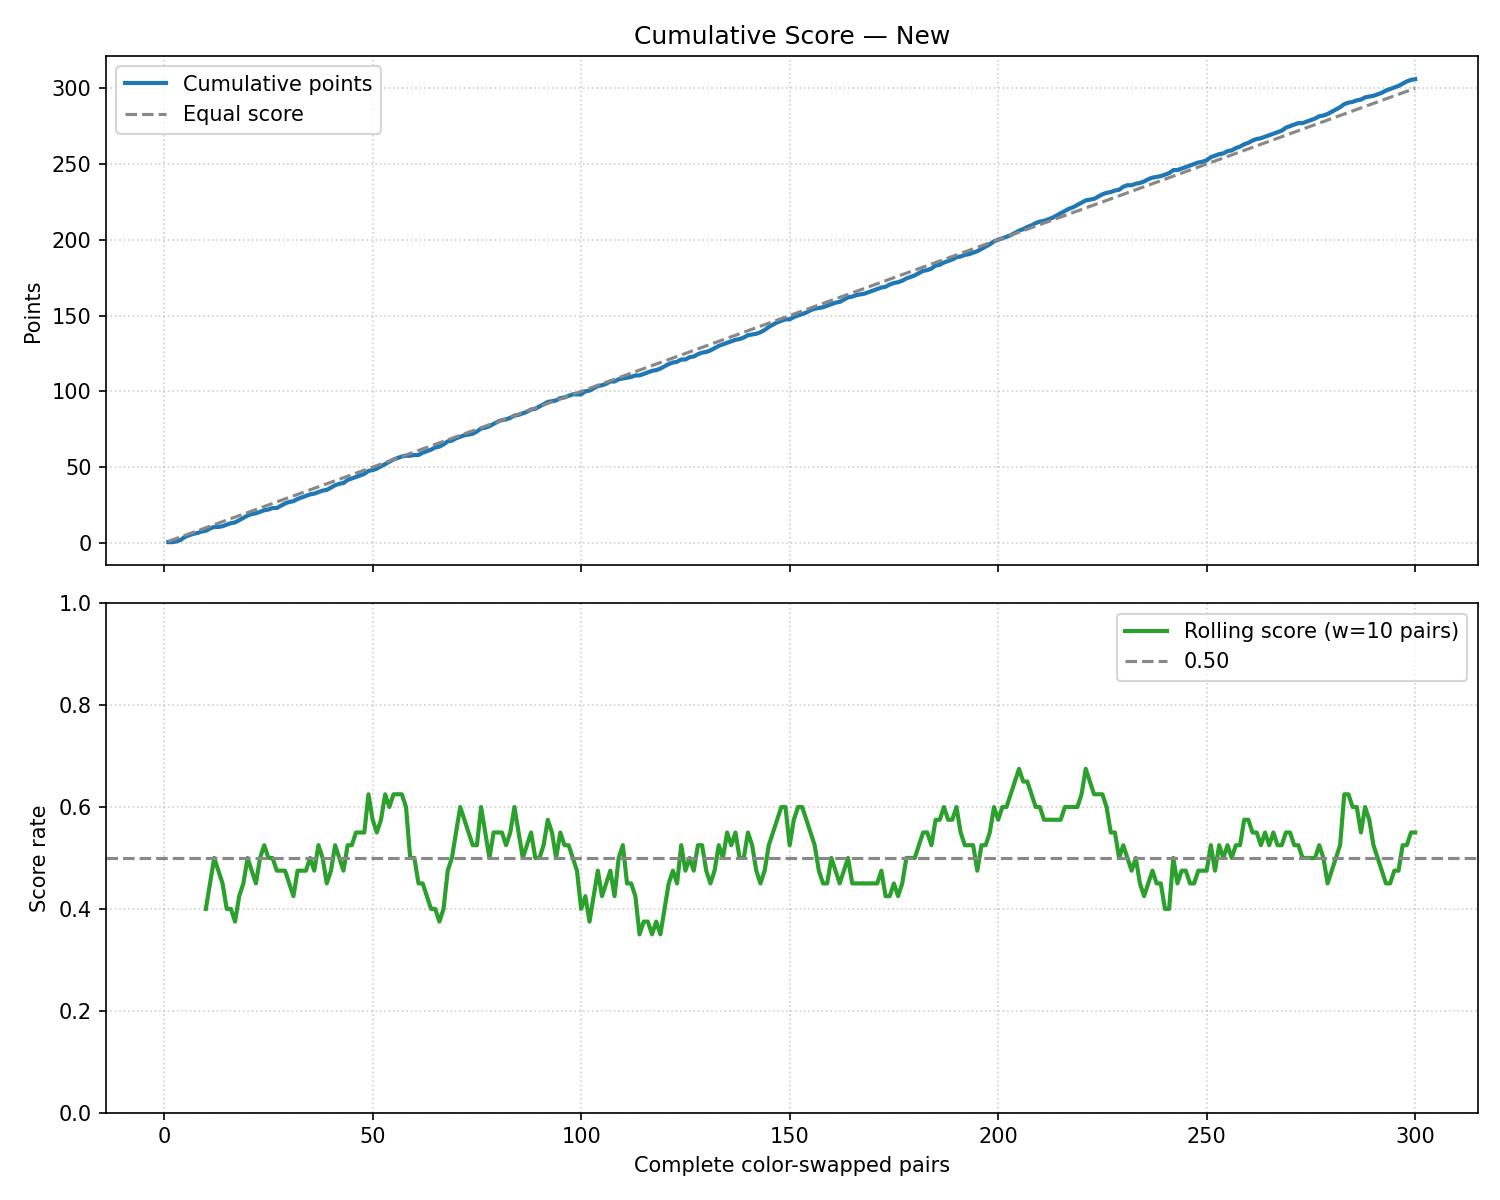


📈 Elo 置信區間收斂圖 (Elo CI)：


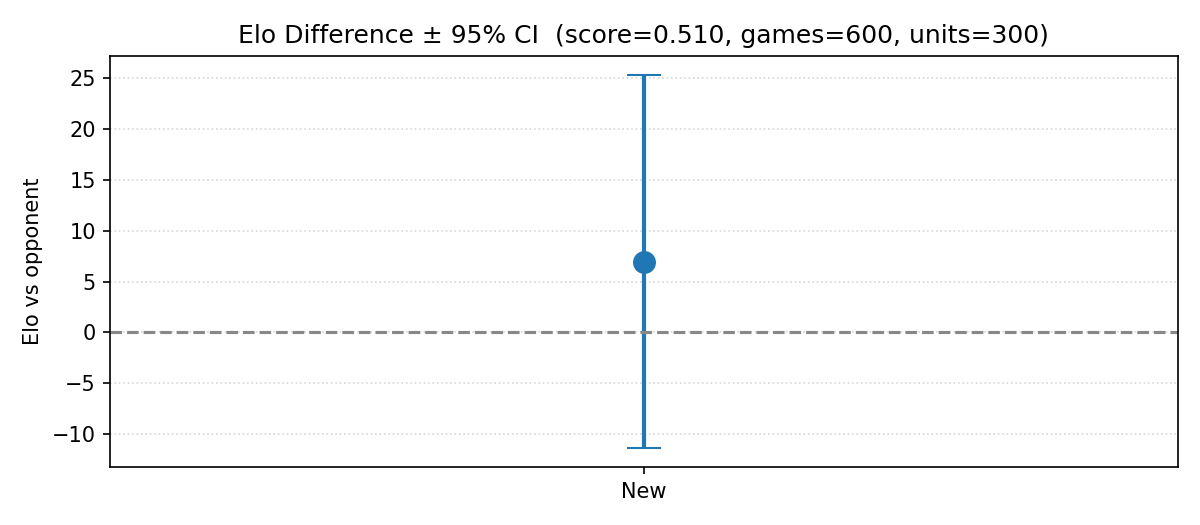


📈 每手搜尋深度 (Depth per Move)：


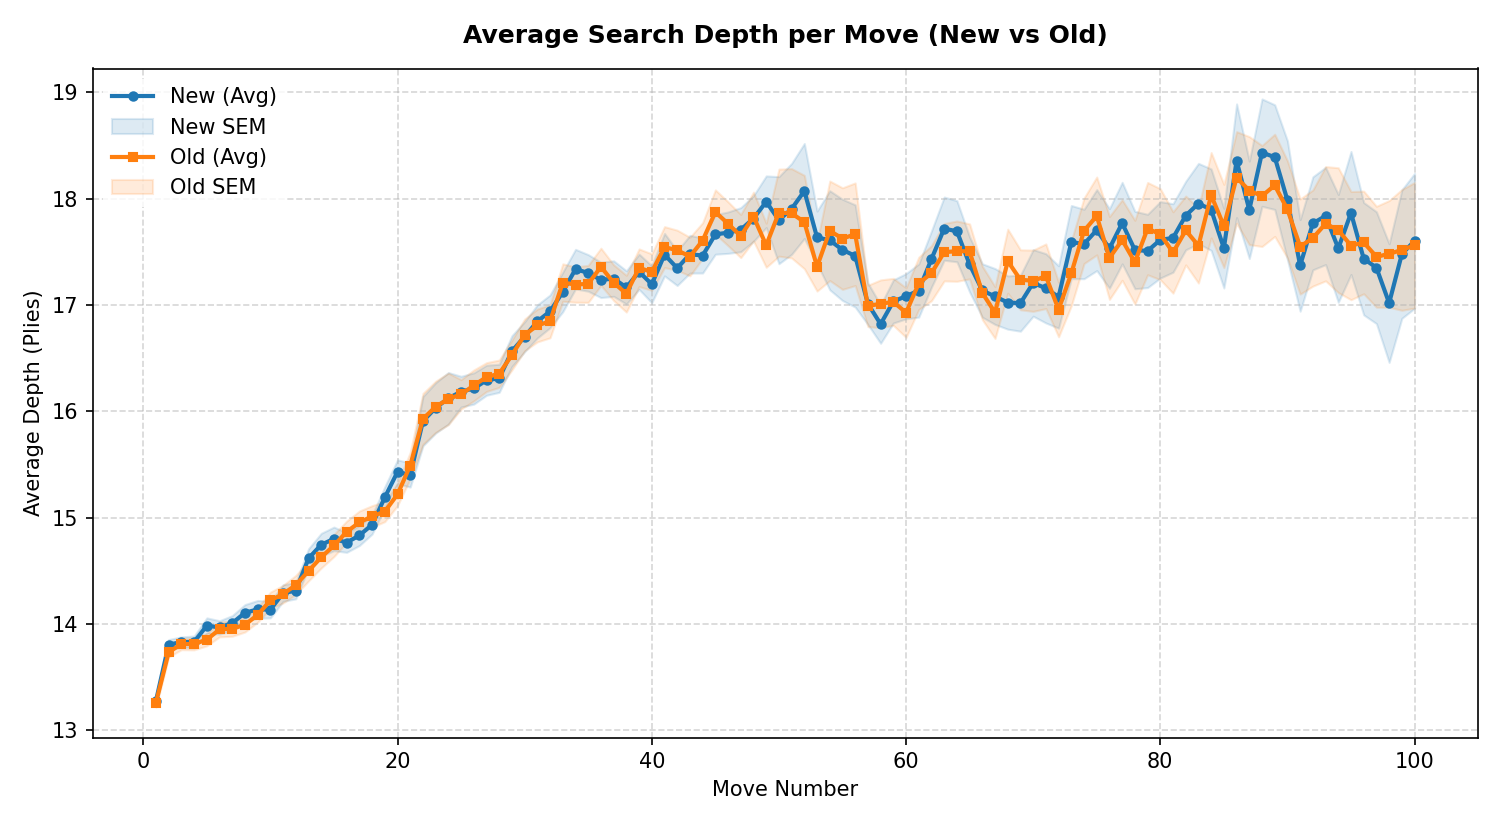


📈 同深度節點比例分佈 (Same-Depth Node Ratio)：


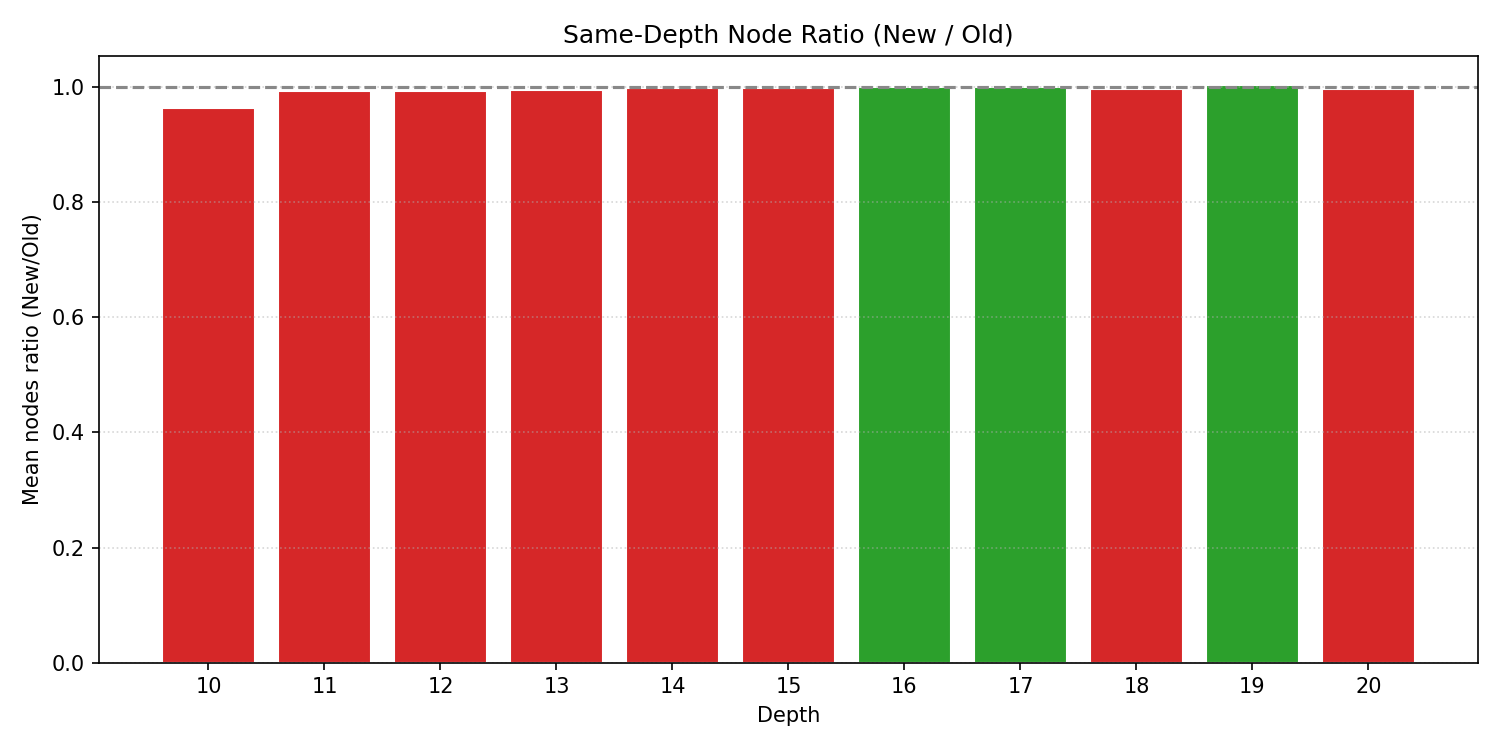


📈 平均節點數 vs 深度散佈 (Avg Nodes vs Depth)：


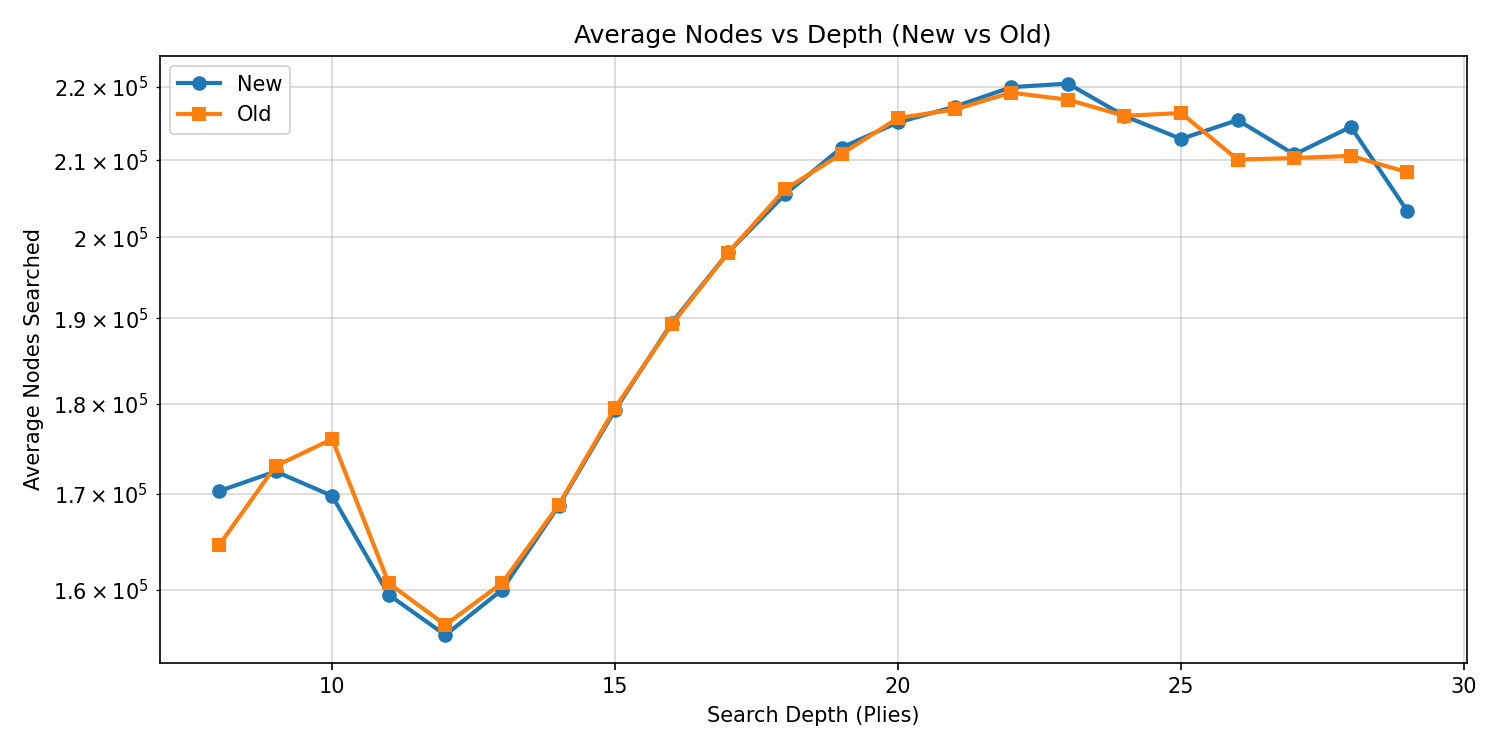


📈 黑白勝負分佈 (WDL by Color)：


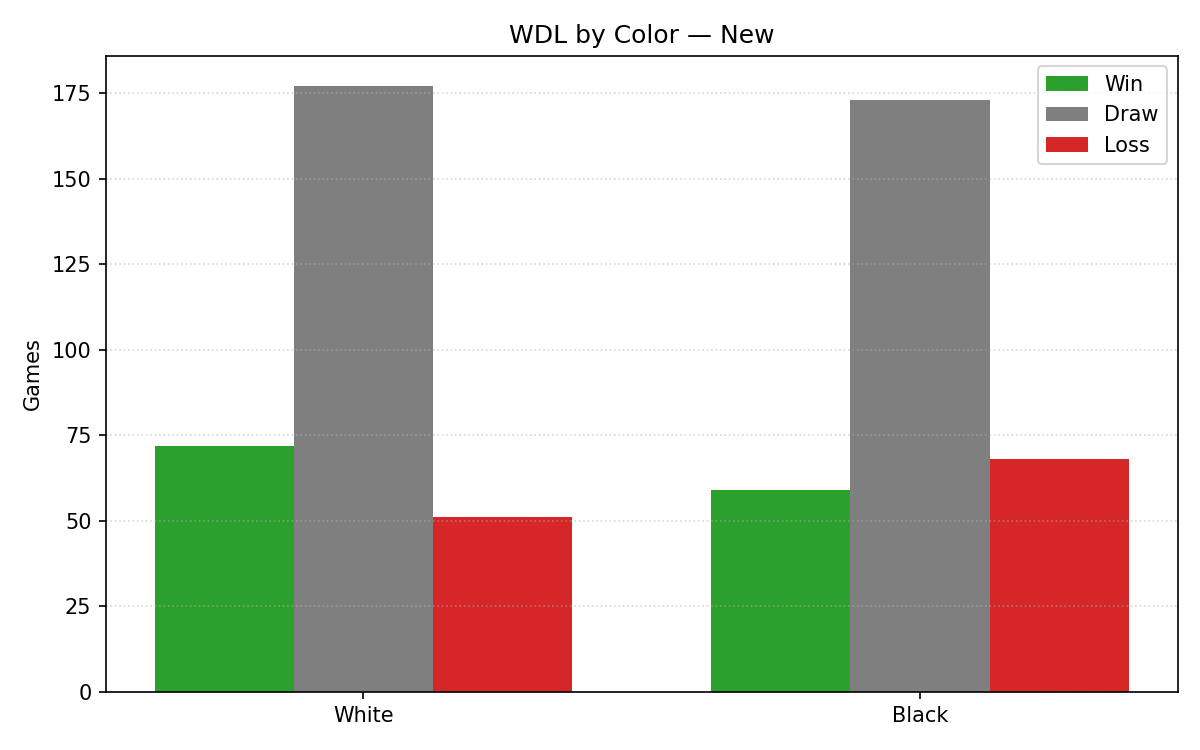

In [69]:
# =====================================================================
# 視覺化關鍵圖表展示
# =====================================================================
import os
from IPython.display import Image, display

charts = [
    ("累積分數曲線 (Cumulative Score)", "tournament_analysis/cumulative_score.png"),
    ("Elo 置信區間收斂圖 (Elo CI)", "tournament_analysis/elo_ci.png"),
    ("每手搜尋深度 (Depth per Move)", "tournament_analysis/depth_per_move.png"),
    ("同深度節點比例分佈 (Same-Depth Node Ratio)", "tournament_analysis/same_depth_node_ratio.png"),
    ("平均節點數 vs 深度散佈 (Avg Nodes vs Depth)", "tournament_analysis/avg_nodes_vs_depth.png"),
    ("黑白勝負分佈 (WDL by Color)", "tournament_analysis/wdl_by_color.png"),
]

for title, path in charts:
    if os.path.exists(path):
        print(f"\n📈 {title}：")
        display(Image(filename=path))


In [70]:
from google.colab import runtime

# 執行這行會直接中斷並釋放目前使用的虛擬機器運算資源
runtime.unassign()
